# Cardiomyocytes across the left-ventricular wall

## Motivation

Cardiomyocytes fill most of a left-ventricular section, but they are not all in the same state. The wall is
loaded differently near the endocardium than near the epicardium, and cardiomyocytes next to fibrotic tissue,
vessels or the endocardial surface live in different surroundings than those deep in the myocardium. With every
2 µm bin of a Visium HD section labelled by a Level-3 cell type, we can ask where in the wall, and next to
whom, cardiomyocytes change their expression.

In this notebook we first ask whether the labels carry the genes we expect of them (ED6 d–f). We then
score a set of stress genes in ventricular cardiomyocytes across the wall of one donor (Fig 3 d), locate the
cardiomyocytes that express the natriuretic peptides *NPPA* and *NPPB* and describe their neighbours
(Fig 3 e–h), search all genes for expression gradients from epicardium to endocardium in three donors (Fig 3 i)
and compare these transcript gradients with protein gradients measured by deep visual proteomics (Fig 3 l).

## Dataset

We work with 11 Visium HD sections of the human left ventricle. Two donors, H0054 and H0063, were sampled at three
positions of the wall (near the epicardium, mid-myocardium, near the endocardium) and donor AH10 at two; these
eight sections carry the transmural analyses. For every section the cell-typing pipeline (`scripts/substrate/`)
has written the objects we start from:

| object | content | fields used here |
|---|---|---|
| 2 µm CMFLAG-clean `AnnData` (`h5ad_2um`) | 2 µm bins × genes, raw counts, after the spillover clean-up | `X`, `obs["L3_label"]`, `obs["x_um"]`, `obs["y_um"]` |
| 8 µm CMFLAG-clean `AnnData` (`h5ad_8um`) | 8 µm bins, for the overview of a section | `obs["L3_label"]`, `obsm["spatial"]` |
| FICTURE pixel decode and input transcripts | one row per decode pixel / per transcript position | `X`, `Y`, `K1`; `gene`, `Count` |
| FICTURE posterior counts and model matrix | genes × Level-3 factors | all |
| registered H&E image and its registration | microscopy image of H0054 endo, affine map from µm to pixels | `M0`, `t0` |

Two further inputs come from outside Visium HD: the snRNA atlas (`h5ad`, layer `normcounts`), from which we take
the mean expression of every gene per Level-3 type, and the table of protein trends across the wall from the
deep-visual-proteomics (DVP) experiment.

The analysis steps live in `hhca.tl` and the figure panels in `hhca.pl`; the command-line scripts in
`scripts/cardiomyocyte/` and `figures/` call the same functions.

## Environment setup

We load the packages and set the scanpy defaults; `style.notebook()` gives the plots of this notebook the font and
open axes of the figure panels. All paths in the configuration are relative to the repository
root, so we work from there.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import squidpy as sq
from scipy import stats

import hhca
from hhca.config import fill, load_config, resolve_roots, section_path
from hhca.grid import spillover_keys
from hhca.pl import style

sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
style.notebook()
np.random.seed(0)
os.chdir(hhca.REPO)

Every parameter of the analysis is set in `config/cardiomyocyte.yaml`: sections, gene lists, thresholds and the
fields shown in the figures. We read the file once; the table lists the donor and the position in the wall of
each section.

In [2]:
cfg = load_config("cardiomyocyte")
all_sections = cfg["slides"]["berlin"] + cfg["slides"]["ah"]
ventricular = cfg["cell_types"]["ventricular"]
section_table = pd.DataFrame.from_dict(cfg["sections"], orient="index")
section_table.loc[all_sections]

,donor,layer
VS_CA_H0054LV_henricke_epi,H0054,epi
VS_CA_H0054LV_henricke_myo,H0054,myo
VS_CA_H0054LV_henricke_endo,H0054,endo
VS_CA_H0063LV_henricke_epi,H0063,epi
VS_CA_H0063LV_henricke_myo,H0063,myo
VS_CA_H0063LV_henricke_endo,H0063,endo
VS_BO_HDZ150319_34_myo,HDZ,myo
VS_BO_2024BH-008_myo,BH008,myo
VS_AH9_LV_FW_epi,AH9,epi
VS_AH10_LV_mid_epi,AH10,epi


## Loading data

The 2 µm bins of a section are an `AnnData` with raw counts. We open all 11 sections without loading the count
matrices into memory; the analysis functions read them in blocks.

In [3]:
sections = {name: ad.read_h5ad(section_path(cfg, "h5ad_2um", name), backed="r") for name in all_sections}
section = "VS_CA_H0054LV_henricke_endo"
adata = sections[section]
adata

AnnData object with n_obs × n_vars = 7015351 × 18085 backed at 'results/substrate/clean_h5ad/h5ad_2um_CMFLAG_clean/VS_CA_H0054LV_henricke_endo.h5ad'
    obs: 'L3_label', 'gcert', 'posterior_max', 'x_um', 'y_um', 'slide'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'build', 'cmflag'

We walk through each step on one section, `VS_CA_H0054LV_henricke_endo`, the endocardial section of donor H0054,
and then run it on all sections it applies to. How many bins does a section have, and how many of them are
ventricular cardiomyocytes?

In [4]:
rows = []
for section_bins in sections.values():
    n_ventricular = (section_bins.obs["L3_label"] == ventricular).sum()
    rows.append({"2 µm bins": section_bins.n_obs, "ventricular CM bins": n_ventricular})
n_bins = pd.DataFrame(rows, index=list(sections))
n_bins["% ventricular CM"] = (100 * n_bins["ventricular CM bins"] / n_bins["2 µm bins"]).round(1)
n_bins

,2 µm bins,ventricular CM bins,% ventricular CM
VS_CA_H0054LV_henricke_epi,7633492,7405224,97.0
VS_CA_H0054LV_henricke_myo,7701469,7475856,97.1
VS_CA_H0054LV_henricke_endo,7015351,6621934,94.4
VS_CA_H0063LV_henricke_epi,7442651,7246811,97.4
VS_CA_H0063LV_henricke_myo,6798677,6583623,96.8
VS_CA_H0063LV_henricke_endo,5739584,5475494,95.4
VS_BO_HDZ150319_34_myo,3626127,3312400,91.3
VS_BO_2024BH-008_myo,3367499,3314151,98.4
VS_AH9_LV_FW_epi,5476477,4966675,90.7
VS_AH10_LV_mid_epi,5066167,4471010,88.3


To see the tissue, we load the 8 µm `AnnData` of our section and plot its Level-3 labels in tissue coordinates,
in the colours of the spatial panels (`style.SPATIAL`).

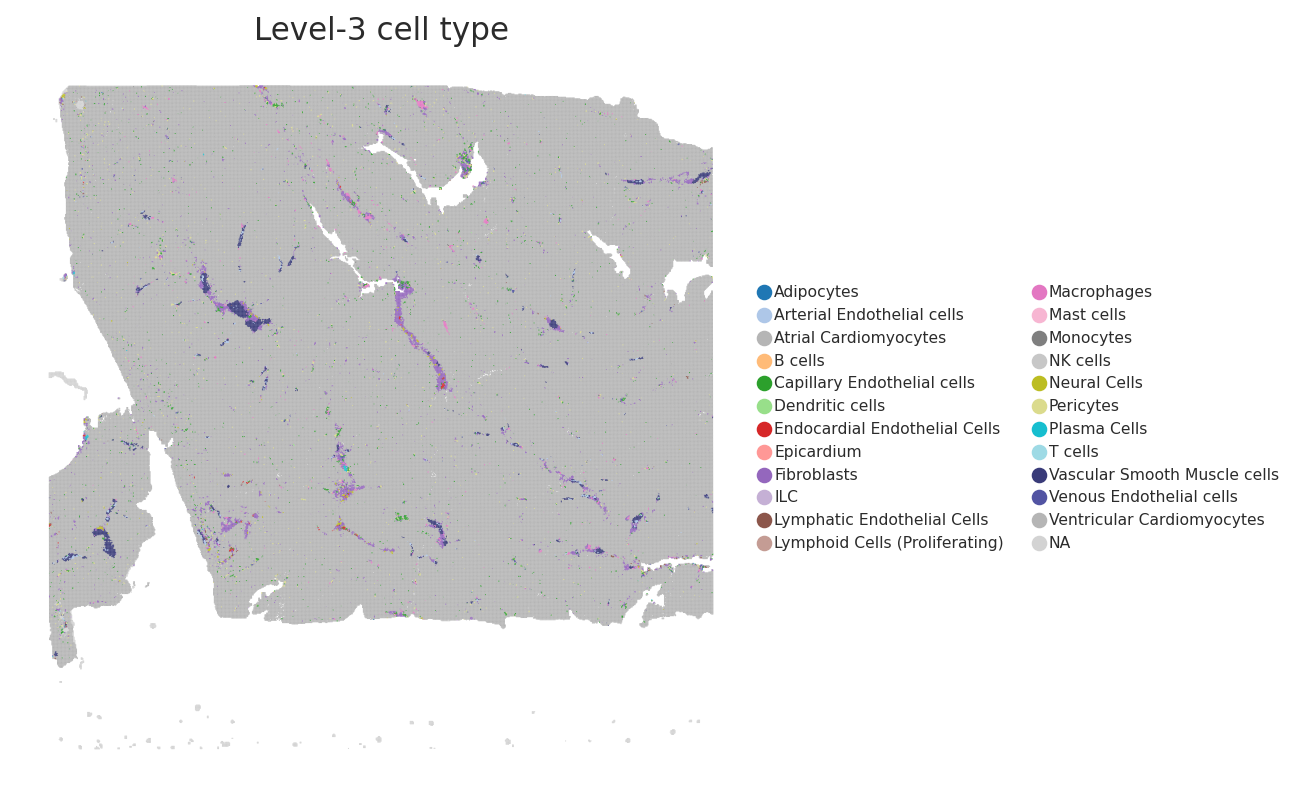

In [5]:
tissue = sc.read_h5ad(section_path(cfg, "h5ad_8um", section))
style.set_colors(tissue, "L3_label", style.SPATIAL)
with plt.rc_context({"figure.figsize": (6, 6)}):
    ax = sc.pl.embedding(
        tissue, basis="spatial", color="L3_label", size=1, legend_fontsize=7, title="Level-3 cell type", show=False
    )
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

Ventricular cardiomyocytes make up between 88.3% and 98.4% of the 2 µm bins of a section, and 94.4% on ours; the
other cell types lie between them.

## Do the labels carry the expected genes?

Everything below rests on the Level-3 label of each bin, so we first compare the labels with known biology.
`hhca.tl.label_pseudobulk` sums the raw counts of a section over the bins of each label, which gives one
expression profile per label.

In [6]:
ed6d = cfg["ed6d"]
counts = hhca.tl.label_pseudobulk(adata, chunk=ed6d["chunk"])
shown_genes = ["MYH7", "DCN", "MYH11", "CD163"]
shown_labels = [ventricular, "Fibroblasts", "Vascular Smooth Muscle cells", "Macrophages"]
counts.loc[shown_genes, shown_labels]

,Ventricular Cardiomyocytes,Fibroblasts,Vascular Smooth Muscle cells,Macrophages
MYH7,139915.0,603.0,152.0,151.0
DCN,139719.0,38971.0,2097.0,1306.0
MYH11,2779.0,398.0,5324.0,60.0
CD163,10583.0,904.0,152.0,2968.0


We repeat the sum on all 11 sections and add the tables up with `hhca.tl.pool_profiles`. For the figure the
labels get their short names and are sorted by name.

In [7]:
per_section = [hhca.tl.label_pseudobulk(section_bins, chunk=ed6d["chunk"]) for section_bins in sections.values()]
profiles = hhca.tl.pool_profiles(per_section)
profiles = profiles.rename(columns=cfg["short_names"]).sort_index(axis=1)
n_genes, n_labels = profiles.shape
total_counts = profiles.to_numpy().sum()
print(f"{n_genes:,} genes x {n_labels} labels, {total_counts:,.0f} counts")

37,082 genes x 23 labels, 1,032,330,524 counts


The configuration lists two or three well-known marker genes for 21 of the labels. `hhca.tl.marker_zscores`
normalises each label's profile to 10,000 counts, takes log1p and z-scores every marker gene across the labels.
For each marker we then ask which label has the highest z-score.

In [8]:
markers = ed6d["markers"]
marker_genes = []
for genes in markers.values():
    marker_genes.extend(genes)
zscores = hhca.tl.marker_zscores(profiles, marker_genes)
best_label = zscores.idxmax(axis=1)

rows = []
for label, genes in markers.items():
    for gene in genes:
        rows.append({"expected": label, "highest": best_label[gene], "z in expected": zscores.loc[gene, label]})
highest = pd.DataFrame(rows, index=marker_genes)
in_own_label = highest["expected"] == highest["highest"]
n_in_own_label = in_own_label.sum()
print(f"{n_in_own_label} of {len(highest)} markers are highest in their own label")
highest[~in_own_label].round(2)

41 of 45 markers are highest in their own label


,expected,highest,z in expected
LYVE1,Lymphatic EC,Macrophages,2.03
IL7R,T cells,ILC,3.16
POSTN,Venous EC,Endocardial EC,0.88
PLVAP,Venous EC,Endocardial EC,2.49


`hhca.pl.label_markers` draws ED6 d: the markers as rows, the labels as columns, and a box around the label each
marker is expected in.

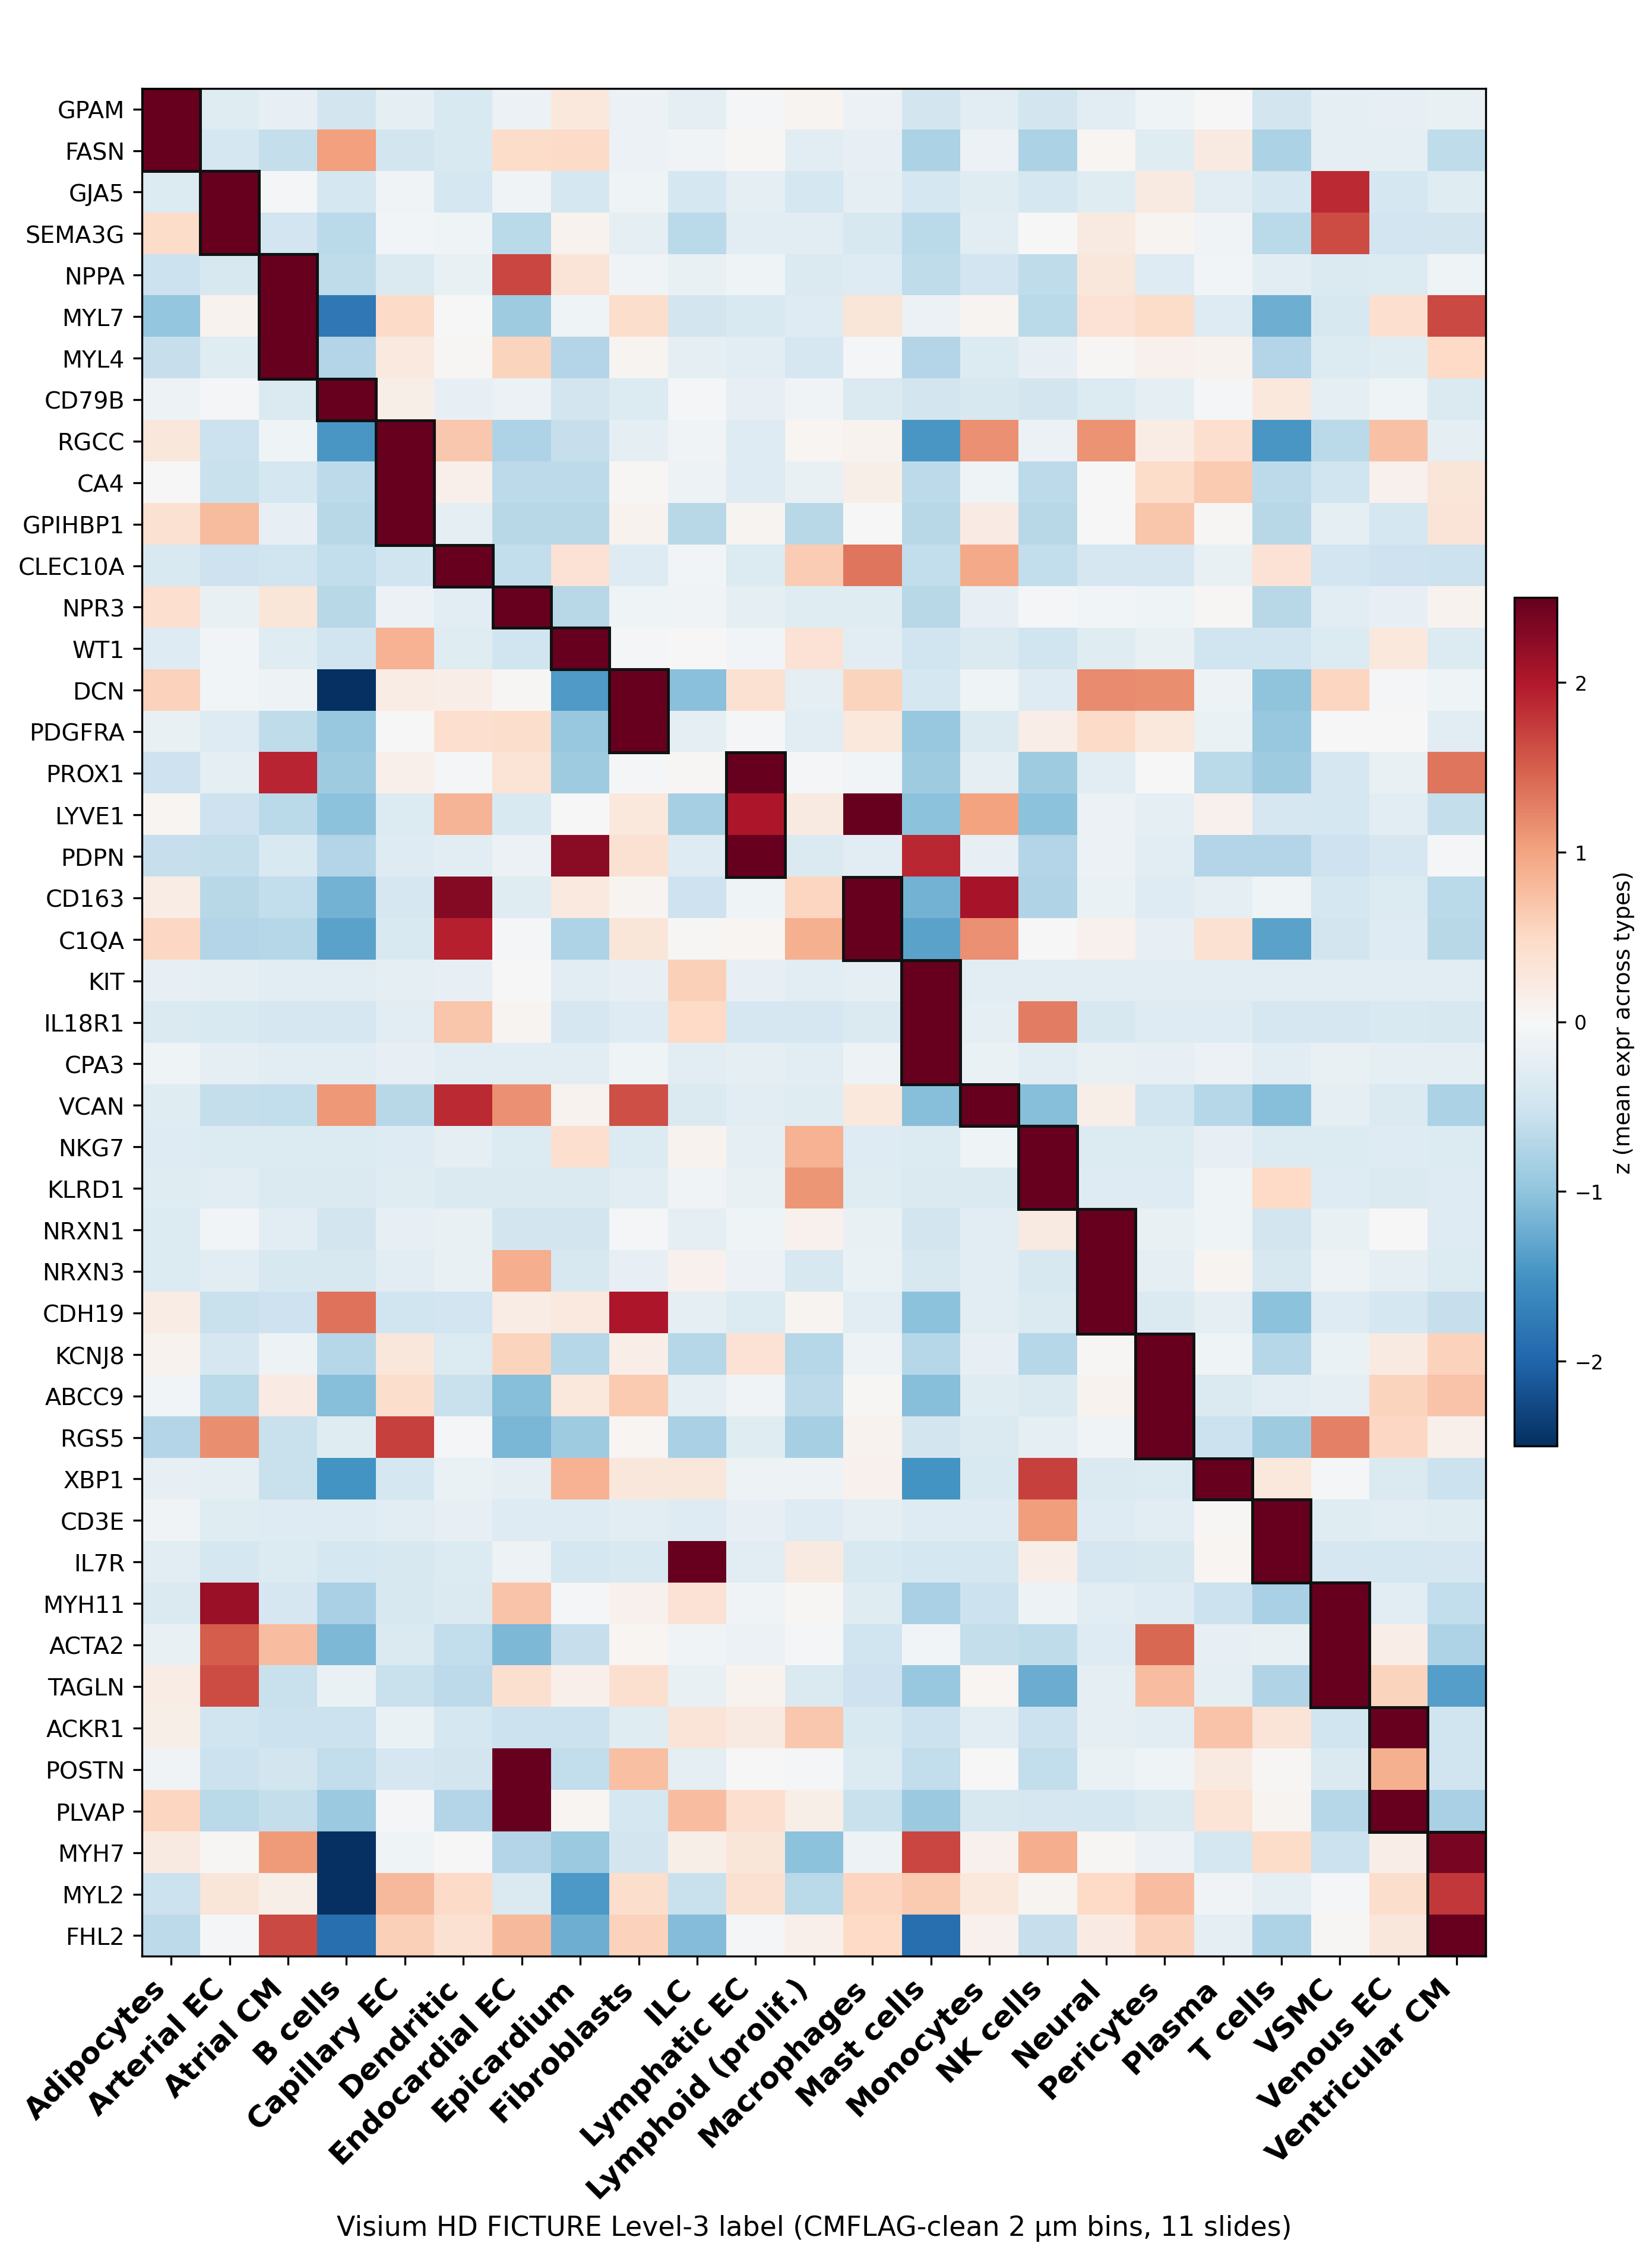

In [9]:
fig = hhca.pl.label_markers(zscores, markers)

Of the 45 markers, 41 are highest in the label they are expected in. The four exceptions stay within related cell
types: *LYVE1* is highest in macrophages, *IL7R* in ILC, and *POSTN* and *PLVAP* in endocardial endothelium.

A handful of hand-picked markers is a narrow test. For a systematic one we compare the labels with the snRNA atlas
they come from. `hhca.tl.type_means` reads the atlas in blocks and returns the mean expression of every gene per
Level-3 type.

In [10]:
atlas_cfg = cfg["atlas"]
atlas_level = atlas_cfg["level"]
atlas_h5ad = fill(atlas_cfg["h5ad"], resolve_roots(cfg))
by_level = hhca.tl.type_means(atlas_h5ad, [atlas_level], layer=atlas_cfg["layer"], chunk=atlas_cfg["chunk"])
atlas = by_level[atlas_level]
n_nuclei = atlas["n_cells"].sum()
n_atlas_genes, n_atlas_types = atlas["mean"].shape
print(f"{n_nuclei:,} nuclei, {n_atlas_genes:,} genes, {n_atlas_types} types")
atlas["n_cells"].sort_values(ascending=False).head().to_frame()

1,459,368 nuclei, 36,601 genes, 24 types


,n_cells
Final Level 3_harmonized,
Ventricular Cardiomyocytes,447587
Fibroblasts,321283
Atrial Cardiomyocytes,121186
Pericytes,112247
Macrophages,89574


We keep the genes and the 23 types of the FICTURE model. `hhca.tl.atlas_markers` then picks, for each type, the
10 genes with the highest ratio to the best other type.

In [11]:
model = pd.read_csv(section_path(cfg, "model_pseudobulk"), sep="\t", index_col=0)
shared_genes = model.index.intersection(atlas["mean"].index)
atlas_means = atlas["mean"].loc[shared_genes, model.columns]
ed6e = cfg["ed6e"]
atlas_marker_genes = hhca.tl.atlas_markers(
    atlas_means, top_n=ed6e["marker_top_n"], min_mean=ed6e["marker_min_mean"], pseudocount=ed6e["pseudocount"]
)
marker_union = []
for genes in atlas_marker_genes.values():
    for gene in genes:
        if gene not in marker_union:
            marker_union.append(gene)
print(f"{len(marker_union)} marker genes for {len(atlas_marker_genes)} types")
top_markers = pd.Series(atlas_marker_genes).str[:5].str.join(", ")
top_markers.head(6).to_frame("top markers")

230 marker genes for 23 types


,top markers
Adipocytes,"PLIN1, GPAM, DGAT2, FASN, GPD1"
Arterial Endothelial cells,"SEMA3G, CSMD1, TSPAN2, GJA5, ACE"
Atrial Cardiomyocytes,"KCNJ3, HAMP, MYL4, SLN, NPPA"
B cells,"NIBAN3, CD79B, P2RX5, TLR10, SELL"
Capillary Endothelial cells,"CD300LG, TNNT3, GPIHBP1, RGCC, TCIM"
Dendritic cells,"ST18, CLEC10A, IL1R2, CLEC5A, MGAM"


On the Visium HD side, FICTURE reports for every section how many counts of each gene it assigned to each factor
(the posterior counts). We add them up over the 11 sections.

In [12]:
posterior_tables = []
for name in all_sections:
    posterior_tables.append(pd.read_csv(section_path(cfg, "posterior", name), sep="\t", index_col=0))
posterior = hhca.tl.pool_profiles(posterior_tables, by_name=False)
posterior.iloc[:5, :4].round(1)

,Adipocytes,Arterial Endothelial cells,Atrial Cardiomyocytes,B cells
gene,,,,
A2M,529.7,11145.8,184.3,0.2
A3GALT2,1.0,0.0,0.0,0.0
A4GALT,40.7,363.3,14.7,0.0
AAAS,69.8,128.4,12.7,1.0
AACS,139.9,58.0,8.9,0.0


`hhca.tl.factor_concordance` brings atlas types and factors into the same space, the z-score of each marker gene
across the 23 types, and correlates every factor with every atlas type. `hhca.tl.concordance_summary` counts the
factors whose best-matching atlas type is their own.

In [13]:
correlation = hhca.tl.factor_concordance(posterior, atlas_means, marker_union)
summary = hhca.tl.concordance_summary(correlation)
print(f"self-match {summary['self_match']} of {len(correlation)}, mean r on the diagonal {summary['diag_mean_r']:.3f}")
own_type_r = pd.Series(np.diag(correlation), index=correlation.index, name="r with own atlas type")
weakest = own_type_r.sort_values().head(5)
weakest.round(3).to_frame()

self-match 23 of 23, mean r on the diagonal 0.834


,r with own atlas type
FICTURE factor,
Epicardium,0.660
ILC,0.687
Mast cells,0.714
T cells,0.759
Dendritic cells,0.763


`hhca.pl.factor_concordance` draws ED6 e.

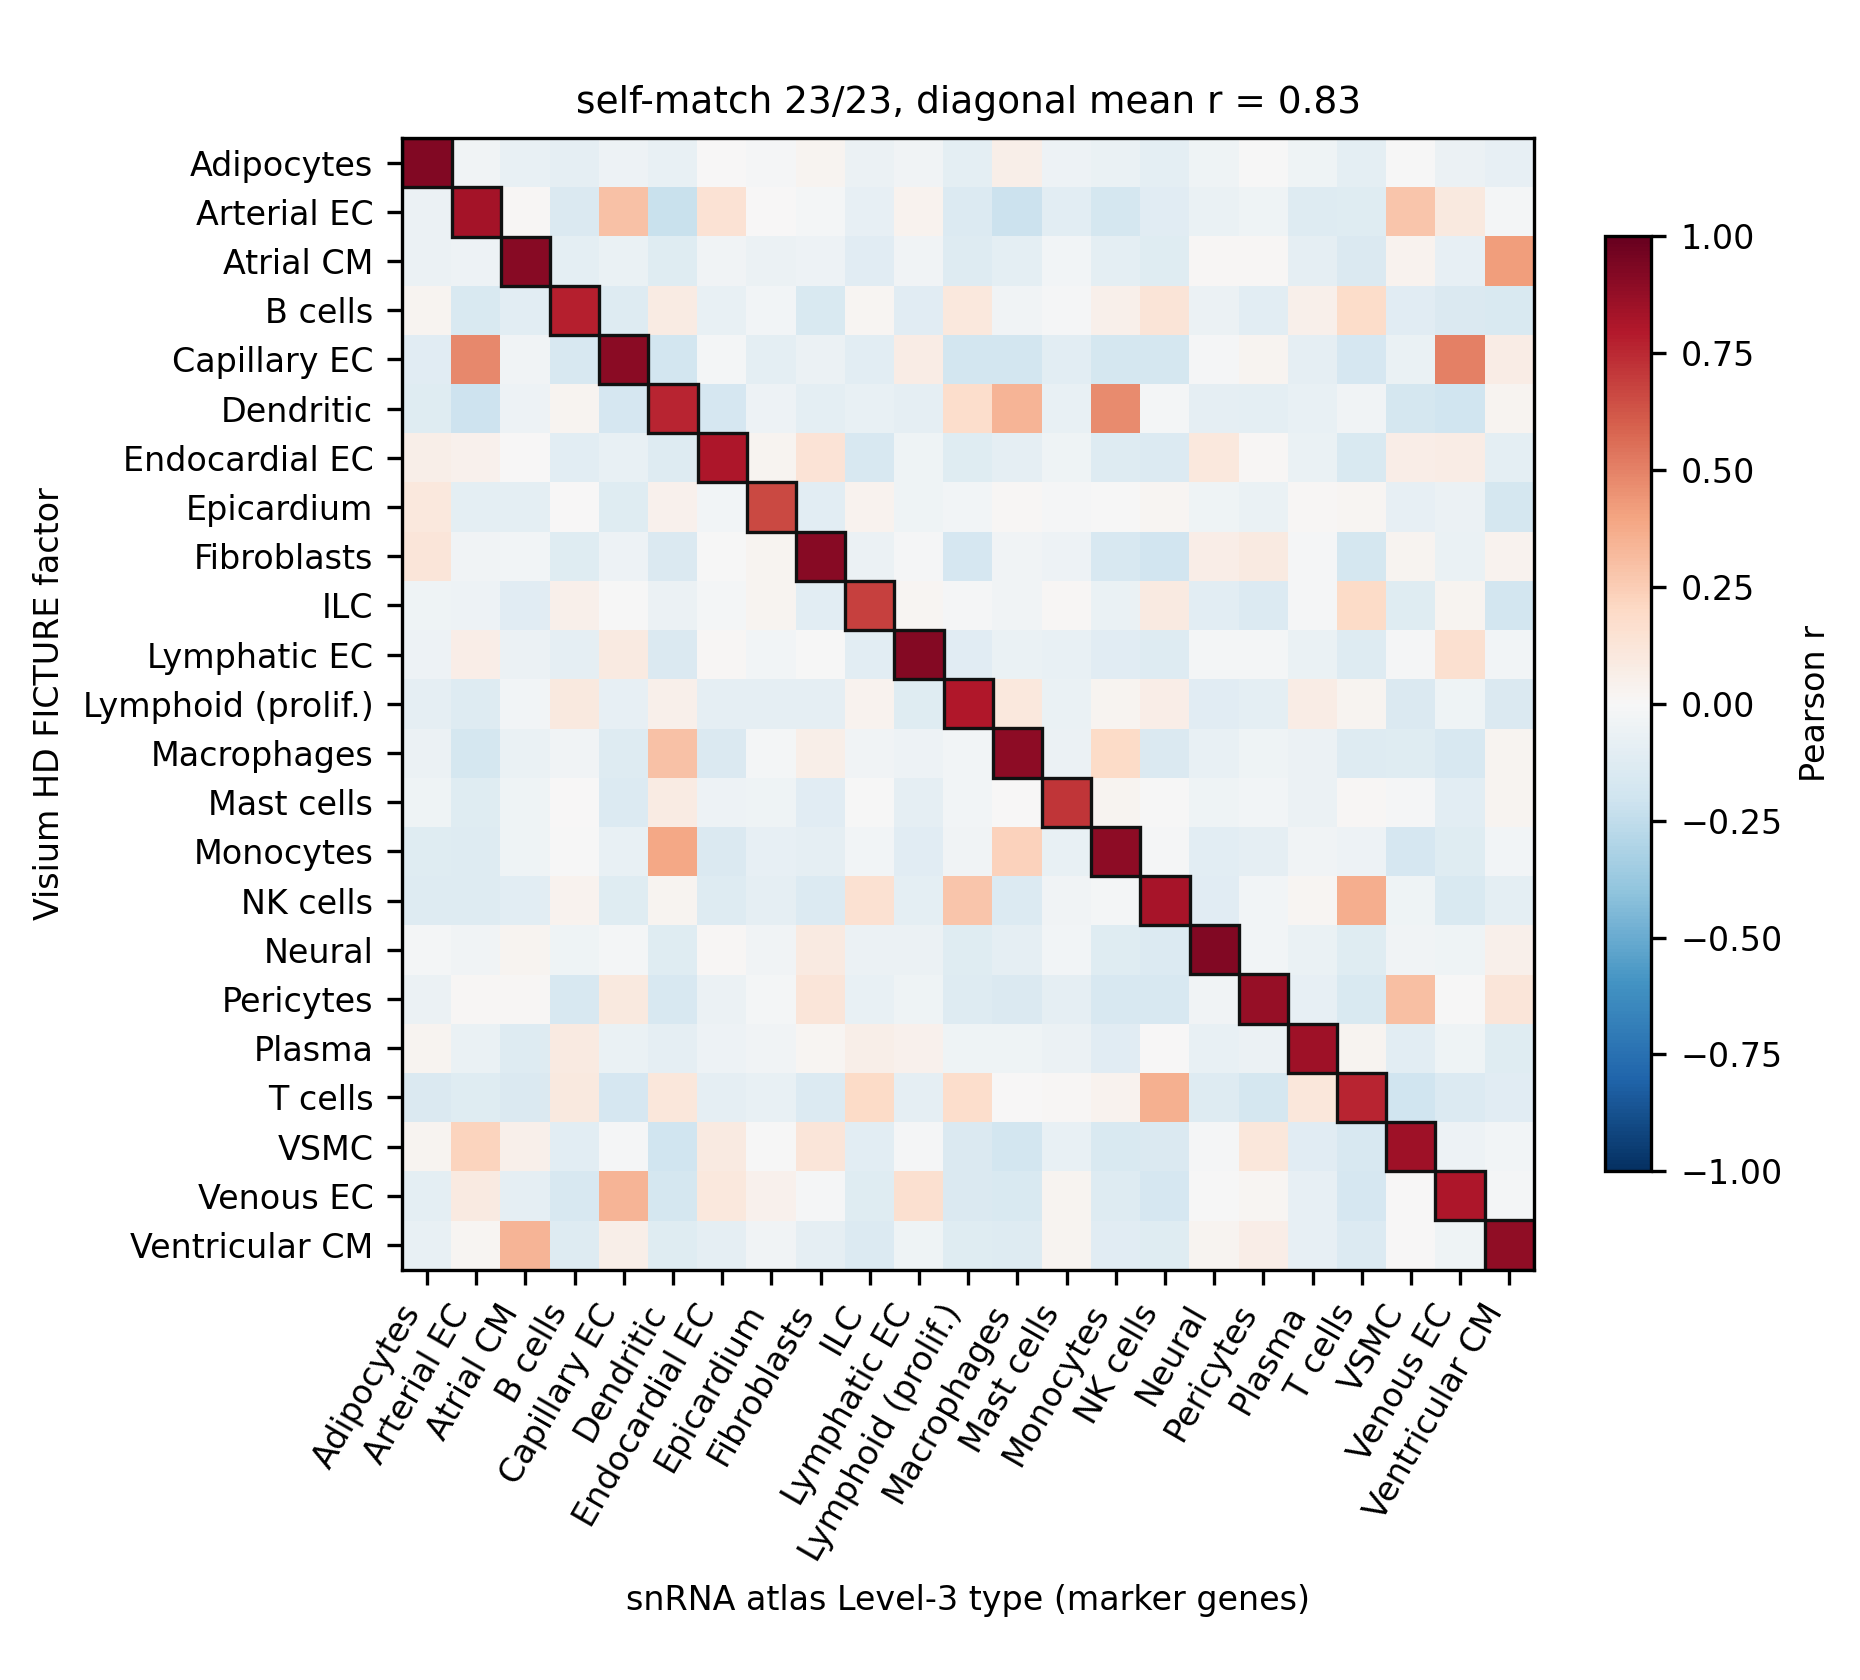

In [14]:
fig = hhca.pl.factor_concordance(correlation, cfg["short_names"])

All 23 factors match their own atlas type best, with a mean correlation of 0.83 on the diagonal. The weakest
matches are epicardium (r = 0.66), ILC (0.69) and mast cells (0.71).

Finally we look at the labels in space. `hhca.tl.label_raster` turns the 2 µm bins of our section into an image
with 4 µm pixels in which non-cardiomyocyte labels are drawn on top of cardiomyocytes, and `hhca.tl.extract_window`
returns the bins of a 340 µm field around a vessel.

In [15]:
ed6f = cfg["ed6f"]
raster = hhca.tl.label_raster(adata, raster_um=ed6f["raster_um"], background=cfg["cell_types"]["cardiomyocytes"])
detail = hhca.tl.extract_window(adata, centre=ed6f["zoom_centre_um"], size_um=ed6f["zoom_size_um"])
raster_height, raster_width = raster["img"].shape[:2]
n_detail_bins = len(detail["x"])
print(f"raster of {raster_width} x {raster_height} pixels, {n_detail_bins:,} bins in the detail")
detail_labels = pd.Series(detail["cats"][detail["code"]])
detail_labels.value_counts().head(6).to_frame("2 µm bins in the detail field")

raster of 1677 x 1469 pixels, 22,475 bins in the detail


,2 µm bins in the detail field
Ventricular Cardiomyocytes,17366
Fibroblasts,2265
Vascular Smooth Muscle cells,1672
Arterial Endothelial cells,310
Capillary Endothelial cells,286
Pericytes,256


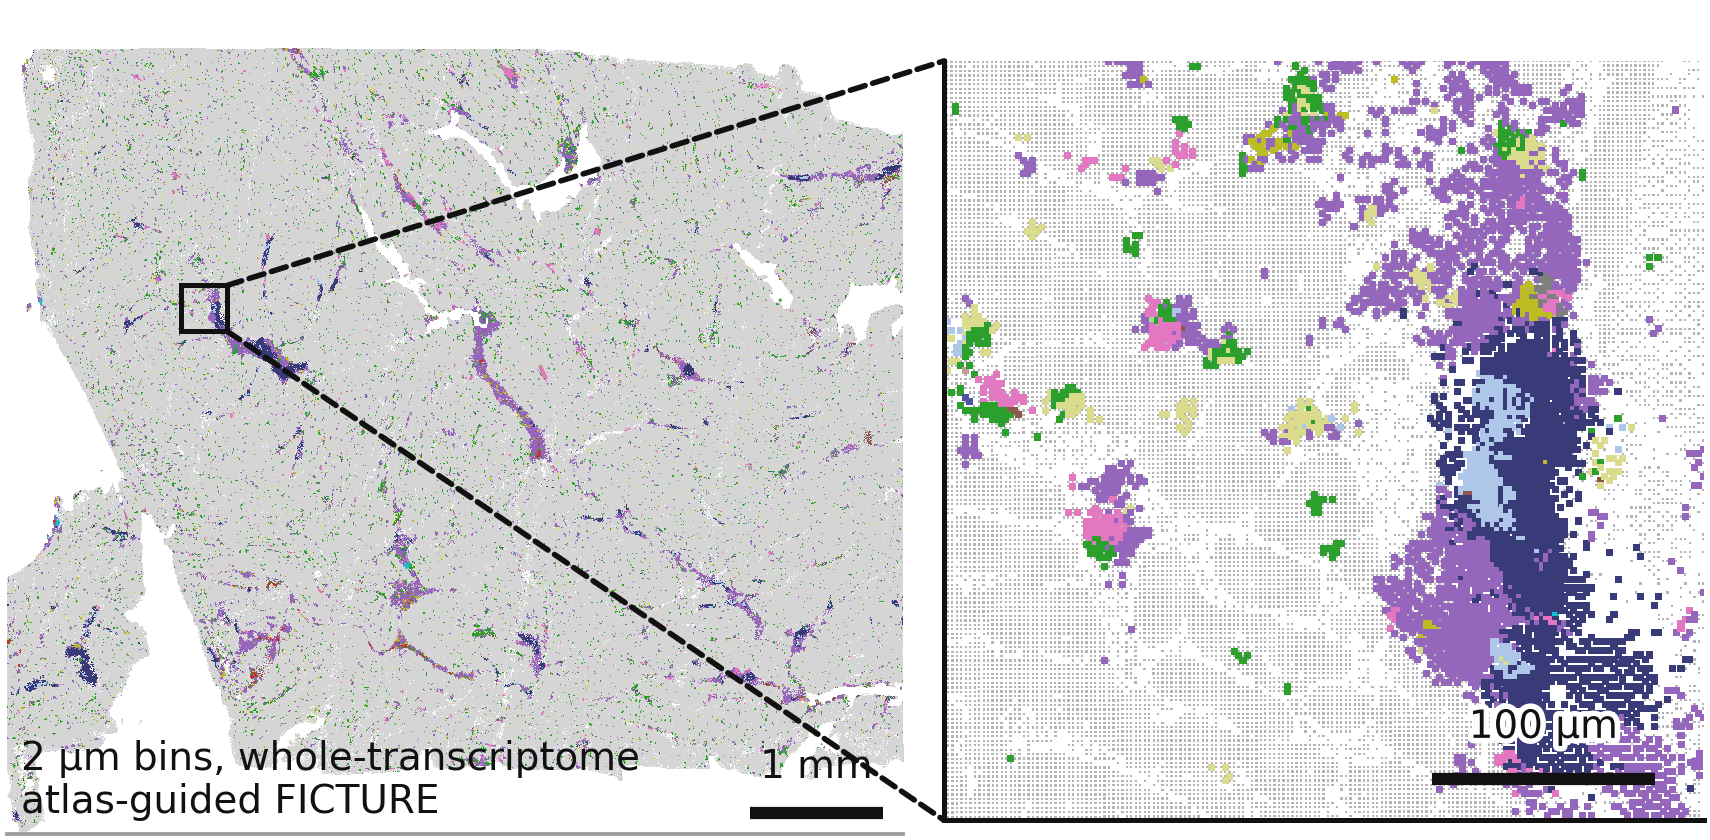

In [16]:
fig = hhca.pl.section_map(raster, detail)

The detail field of ED6 f holds 22,475 bins, among them 1,672 smooth-muscle and 310 arterial endothelial bins
around the vessel.

## Stress score across the wall

The subendocardium carries the highest wall stress. Do ventricular cardiomyocytes show it in their expression? We
use the three sections of donor H0054 and a set of 18 stress genes.

In [17]:
fig3d = cfg["fig3d"]
stress_genes = fig3d["genesets"]["stress18"]
print(", ".join(stress_genes))

NPPA, NPPB, ANKRD1, ACTA1, MYH7, TNNI1, XIRP2, XIRP1, CSRP3, FHL1, MYOT, FLNC, DES, CRYM, CMYA5, BAG3, CRYAB, POSTN


`hhca.tl.log_cp10k` reads the three sections, keeps the ventricular-cardiomyocyte bins, scales every bin to
10,000 counts over all genes and returns log1p of the stress genes. The bins of the three sections come back in
one `AnnData`, with the section in `obs["section"]`.

In [18]:
h0054_sections = {layer: sections[name] for layer, name in fig3d["sections"].items()}
cm_bins = hhca.tl.log_cp10k(h0054_sections, stress_genes, cell_type=ventricular, chunk=fig3d["chunk"])
cm_bins

AnnData object with n_obs × n_vars = 21503014 × 18
    obs: 'section', 'x_um', 'y_um'
    obsm: 'spatial'

`hhca.tl.score_gene_sets` z-scores every gene against all bins of the object, so that the three sections share
one reference, and takes the mean over the genes of the set. The score is added to `cm_bins.obs`.

In [19]:
hhca.tl.score_gene_sets(cm_bins, {"stress18": stress_genes})
stress_by_section = cm_bins.obs.groupby("section", observed=True)["stress18"]
stress_by_section.agg(["size", "mean", "median"]).round(4)

,size,mean,median
section,,,
epi,7405224,-0.0132,-0.1347
myo,7475856,-0.0111,-0.1347
endo,6621934,0.0273,-0.0247


A single 2 µm bin holds few transcripts, so the score of one bin is noisy. We therefore cut each section into
tiles of 650 µm and rank the tiles with at least 4,000 cardiomyocyte bins by their mean score
(`hhca.tl.rank_tiles`).

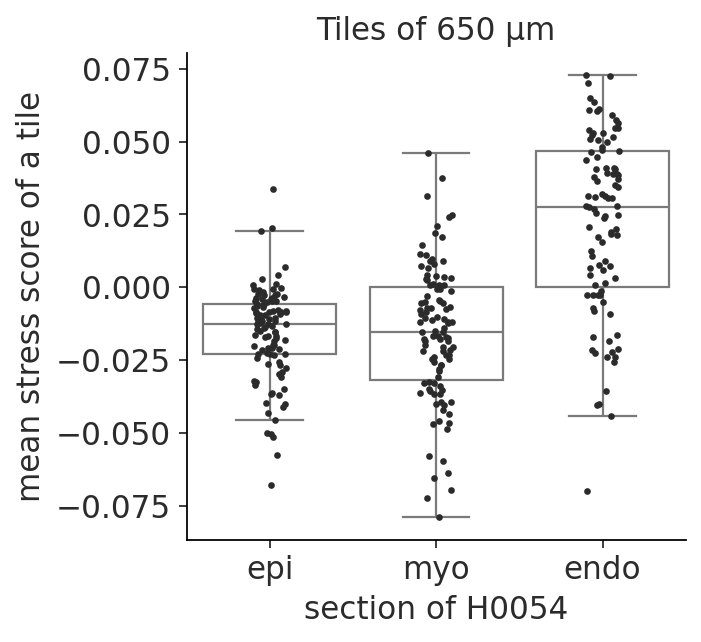

In [20]:
tile_um = fig3d["field_um"]
tiles = []
for layer in h0054_sections:
    layer_bins = cm_bins[cm_bins.obs["section"] == layer]
    ranking = hhca.tl.rank_tiles(layer_bins, "stress18", field_um=tile_um, min_bins=fig3d["min_tile_bins"])
    ranking.insert(0, "section", layer)
    tiles.append(ranking)
tiles = pd.concat(tiles)

ax = sns.boxplot(tiles, x="section", y="mean", color="white", linecolor=style.MUTED, fliersize=0)
sns.stripplot(tiles, x="section", y="mean", color=style.INK, size=3, ax=ax)
ax.set(xlabel="section of H0054", ylabel="mean stress score of a tile", title=f"Tiles of {tile_um:.0f} µm")
plt.show()

In [21]:
tile_means = [tiles.loc[tiles["section"] == layer, "mean"] for layer in h0054_sections]
kruskal = stats.kruskal(*tile_means)
print(f"Kruskal-Wallis H = {kruskal.statistic:.1f}, p = {kruskal.pvalue:.1e}")
tiles.groupby("section", sort=False)["mean"].agg(["size", "median"]).round(4)

Kruskal-Wallis H = 92.1, p = 1.0e-20


,size,median
section,,
epi,107,-0.0125
myo,107,-0.0154
endo,96,0.0277


The figure shows one field per section: the tile at the 10th percentile of the ranking for the epicardial
section, the median tile for the mid-myocardium and the tile at the 90th percentile for the endocardial section
(`hhca.tl.tile_at`).

In [22]:
fields_3d = {}
for layer in h0054_sections:
    layer_tiles = tiles[tiles["section"] == layer]
    fields_3d[layer] = hhca.tl.tile_at(layer_tiles, fig3d["pick"][layer], field_um=tile_um)
field_table = pd.DataFrame.from_dict(fields_3d, orient="index", columns=["xlo", "xhi", "ylo", "yhi"])
field_table.round(1)

,xlo,xhi,ylo,yhi
epi,8996.8,9646.8,412.3,1062.3
myo,3806.6,4456.6,4955.9,5605.9
endo,6917.6,7567.6,823.0,1473.0


`hhca.tl.field_grid` averages the score of a field on a 5 µm grid, and `hhca.pl.stress_fields` draws Fig 3 d from
the three grids.

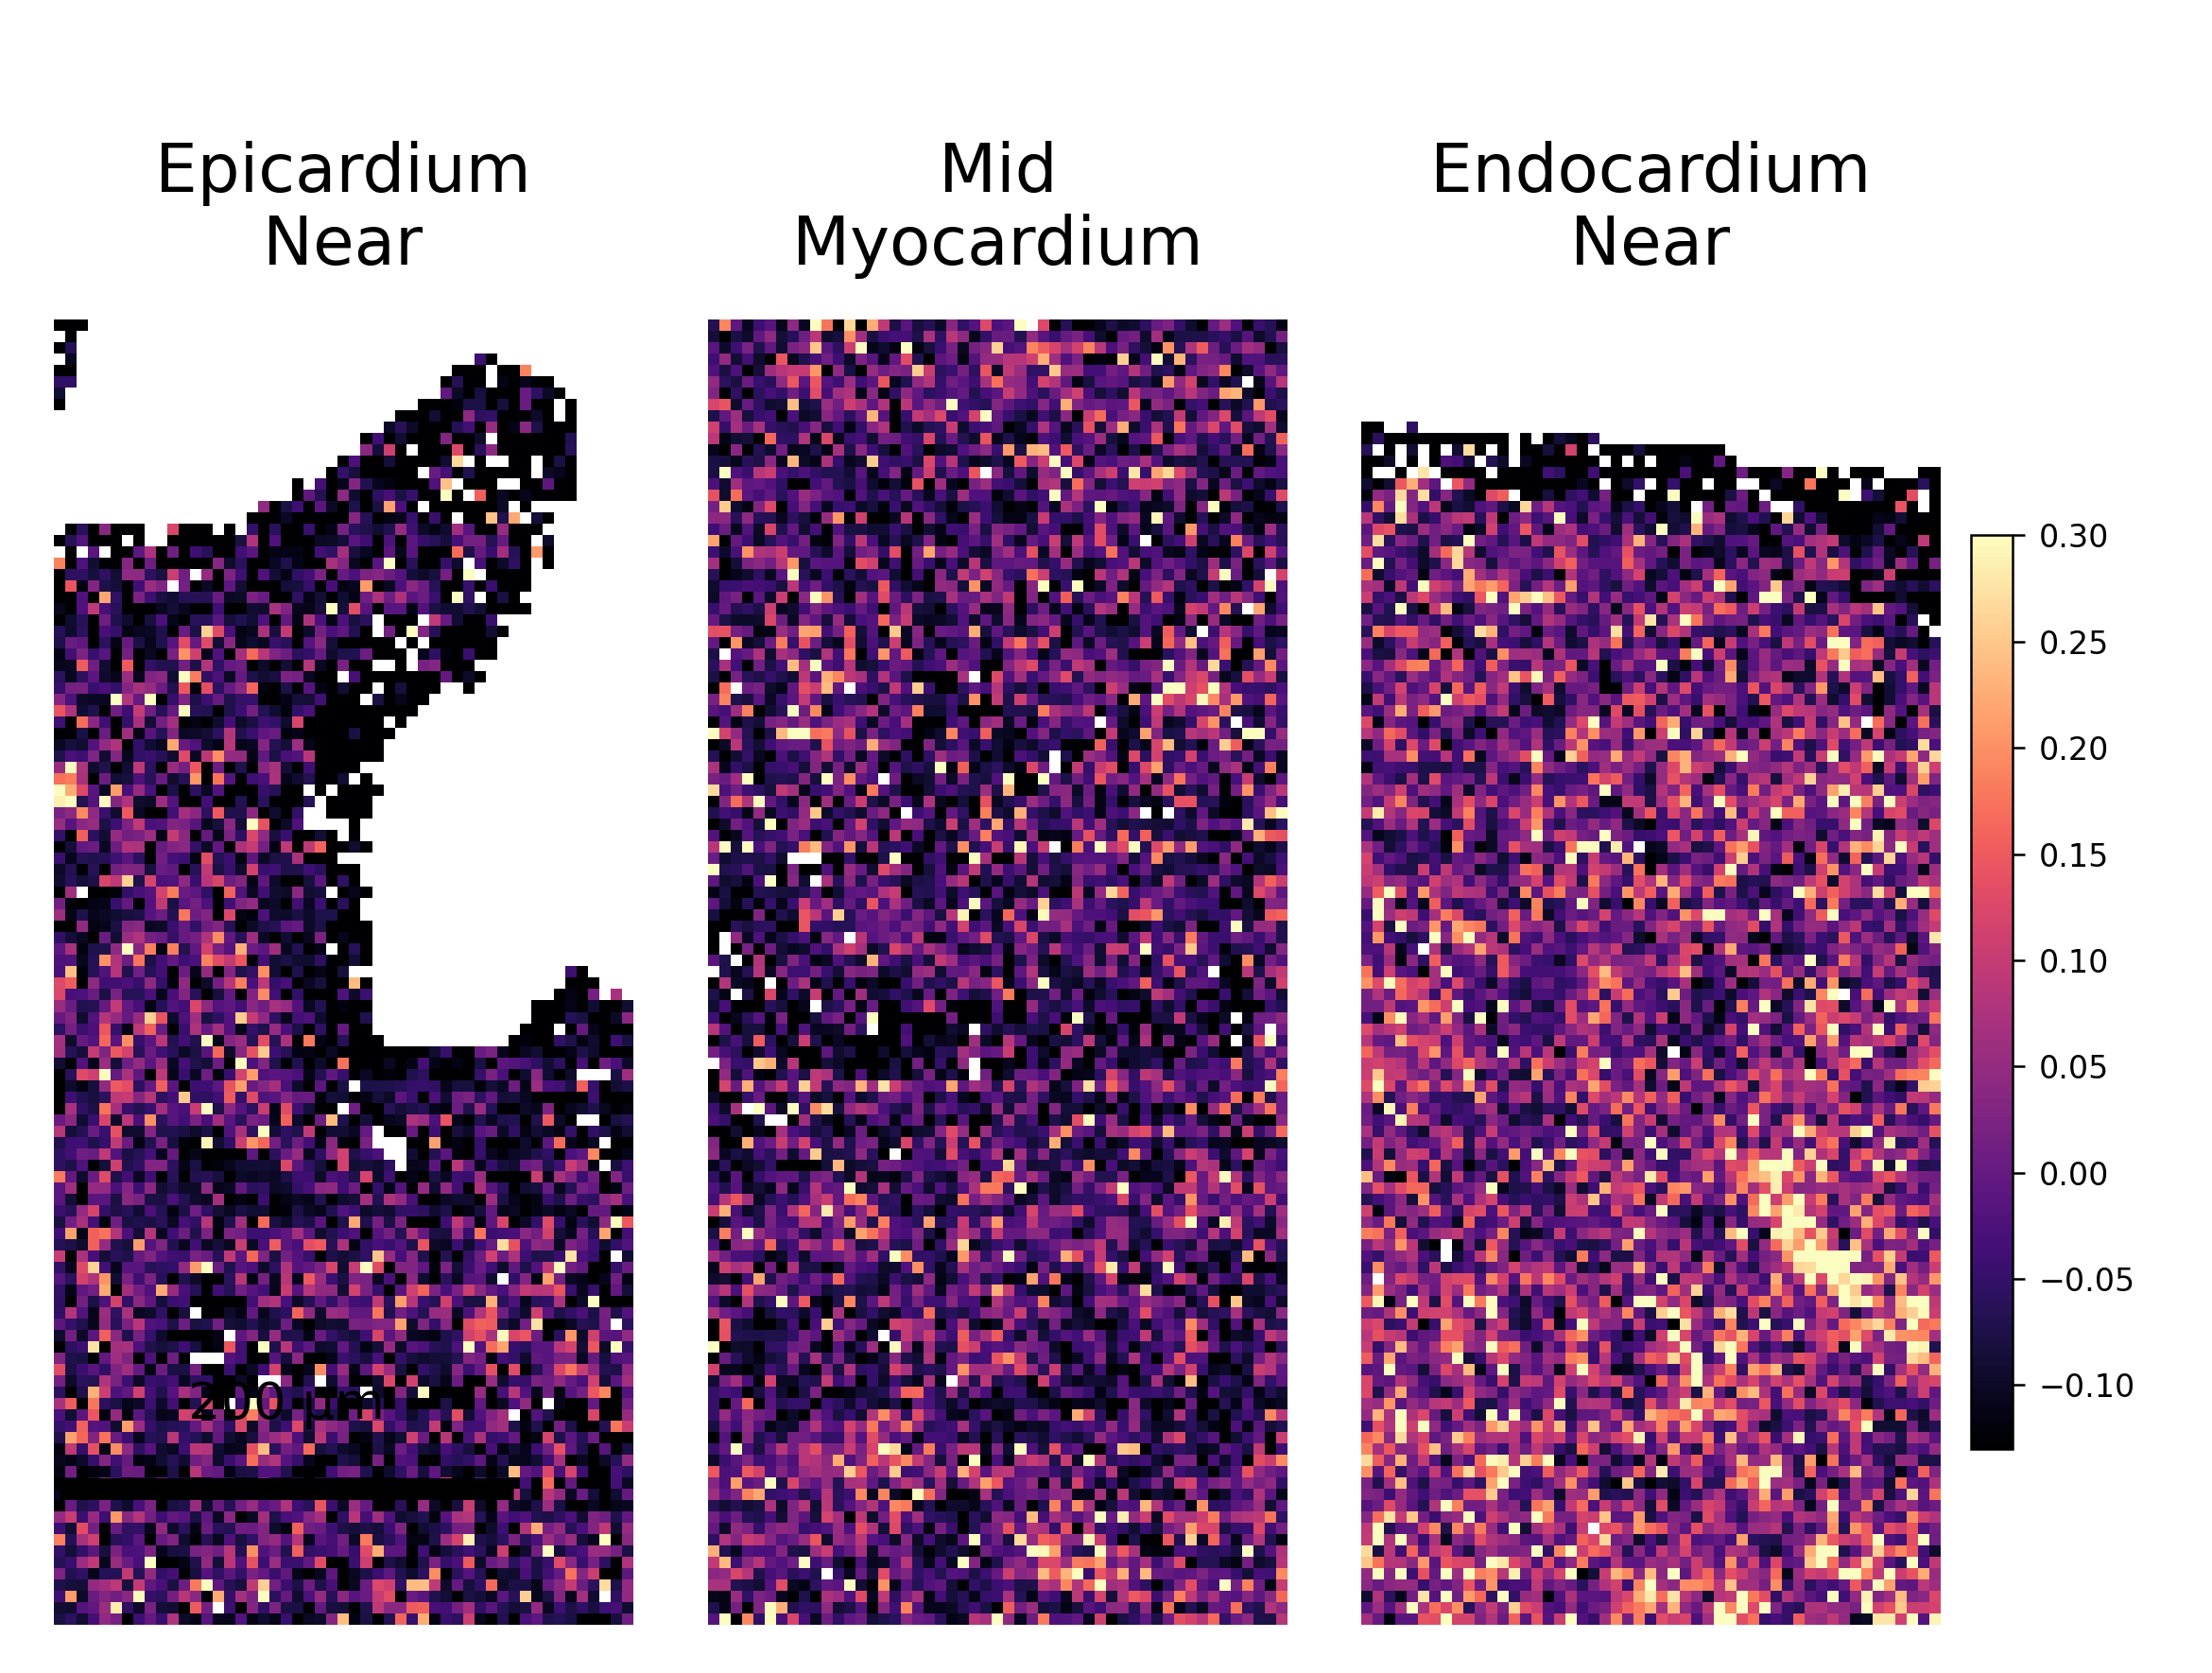

In [23]:
grids = {}
for layer in h0054_sections:
    layer_bins = cm_bins[cm_bins.obs["section"] == layer]
    grids[layer] = hhca.tl.field_grid(
        layer_bins, "stress18", fields_3d[layer], field_um=tile_um, grid_um=fig3d["grid_um"]
    )
fig = hhca.pl.stress_fields(grids, fields_3d, fig3d["strip"], fig3d["vmin_vmax"])

The mean stress score is −0.013 in the epicardial and −0.011 in the mid-myocardial section, against 0.027 in the
endocardial section. The tiles show the same shift (medians −0.013, −0.015 and 0.028; Kruskal–Wallis H = 92.1,
p = 1.0e-20).

## *NPPA*-high cardiomyocytes and their neighbours

Two of the stress genes, *NPPA* and *NPPB*, encode the natriuretic peptides that cardiomyocytes release under
strain. Where are they expressed? We take a 500 µm field under the endocardium of our section and the counts of
the two genes in its bins.

In [24]:
fig3e = cfg["fig3e"]
field = hhca.tl.extract_window(adata, centre=fig3e["centre_um"], size_um=fig3e["size_um"], genes=fig3e["genes"])
field_labels = pd.Series(field["cats"][field["code"]])
expressing_bins = {}
for gene in fig3e["genes"]:
    expressing_bins[gene] = field_labels[field[gene] > 0].value_counts()
by_label = pd.DataFrame(expressing_bins).fillna(0).astype(int)
by_label.sort_values("NPPA", ascending=False).head(5)

,NPPA,NPPB
Ventricular Cardiomyocytes,1397,33
Atrial Cardiomyocytes,520,1
Fibroblasts,162,1
Neural Cells,21,0
Capillary Endothelial cells,21,0


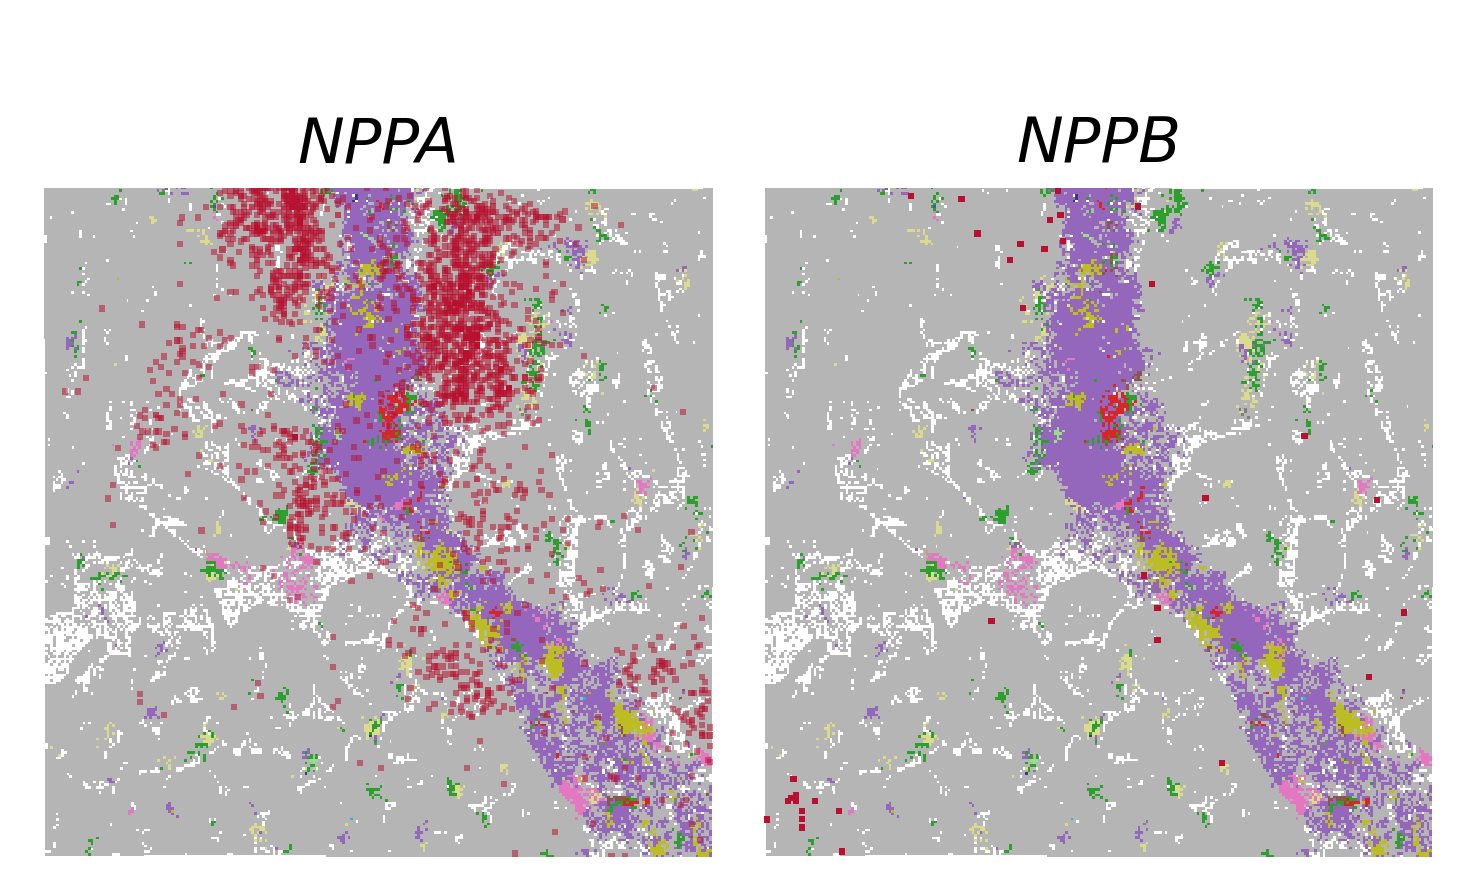

In [25]:
fig = hhca.pl.expressing_bins(field, fig3e["genes"])

In this field 1,397 ventricular-cardiomyocyte bins carry *NPPA* counts and 33 carry *NPPB*. *NPPA* is also found
in 520 bins labelled as atrial cardiomyocytes and in 162 fibroblast bins.

To describe the surroundings of such cardiomyocytes on a whole section, we move to a coarser unit. For this step
we start from the decode pixels and the transcripts that went into FICTURE, and leave out everything that lies in
a 2 µm bin flagged by CMFLAG. `hhca.tl.niche_bins` counts both on a 10 µm grid: every bin gets the share of its
pixels per cell-type group and the density of *NPPA* and *NPPB* per 1,000 counts.

In [26]:
niche = cfg["niche"]
with open(section_path(cfg, "factor_order")) as handle:
    factor_order = json.load(handle)

pixels = hhca.io.read_decode(section_path(cfg, "decode", section))
spillover = spillover_keys(section_path(cfg, "niche_flags", section))
bins = hhca.tl.niche_bins(
    pixels,
    section_path(cfg, "transcripts", section),
    factor_order,
    niche["groups"],
    genes=niche["genes"],
    spillover=spillover,
    grid_um=niche["grid_um"],
    min_pixels=niche["min_pixels"],
    chunksize=niche["transcript_chunk"],
)
shown_columns = ["x_um", "y_um", "npix", "total_counts", "NPPA", "NPPA_cp1k", "frac_CM", "frac_fibroblast"]
bins[shown_columns].head()

,x_um,y_um,npix,total_counts,NPPA,NPPA_cp1k,frac_CM,frac_fibroblast
0,2002.599976,828.0,4,110.0,0.0,0.0,1.0,0.0
1,2012.599976,828.0,5,401.0,0.0,0.0,1.0,0.0
2,2022.599976,828.0,5,328.0,0.0,0.0,0.8,0.0
3,2032.599976,828.0,5,238.0,0.0,0.0,0.4,0.0
4,2042.599976,828.0,5,284.0,0.0,0.0,1.0,0.0


`hhca.tl.niche_metrics` adds the surroundings of each bin: the share of fibroblast, endocardial, vessel and
immune pixels within 30 µm, and the distance to the nearest bin that is rich in fibroblasts (at least 30% of its
pixels), endocardium (10%) or vessel cells (30%).

In [27]:
bins = hhca.tl.niche_metrics(bins, niche["neighbourhoods"], niche["rich"], radius_um=niche["radius_um"])
shown_columns = ["nbhd_fibroblast", "nbhd_vessel", "dist_fibroblast_um", "dist_endocardial_um", "dist_vessel_um"]
metric_summary = bins[shown_columns].describe()
metric_summary.loc[["count", "50%", "max"]].round(2)

,nbhd_fibroblast,nbhd_vessel,dist_fibroblast_um,dist_endocardial_um,dist_vessel_um
count,325851.00,325851.00,325851.00,325851.00,325851.00
50%,0.00,0.01,60.83,812.16,42.43
max,0.96,1.00,320.00,3439.91,245.15


Reading the transcripts of a section takes a few minutes, so for the tests on all 11 sections we load the bin
tables written by `scripts/cardiomyocyte/run_niche_slide.py`, which makes the same two calls on every section.

In [28]:
bin_tables = {}
n_niche_bins = 0
for name in all_sections:
    bin_tables[name] = pd.read_csv(f"results/cardiomyocyte/fig3fgh/bins/niche_bins_{name}.csv.gz")
    n_niche_bins += len(bin_tables[name])
print(f"all sections: {n_niche_bins:,} bins")

all sections: 3,195,307 bins


A cardiomyocyte bin has at least half of its pixels labelled as cardiomyocyte. Among these, `hhca.tl.gene_high`
marks the bins in the top decile of the non-zero *NPPA* densities.

314,524 cardiomyocyte bins, 990 NPPA-high (at least 20.0 per 1,000)


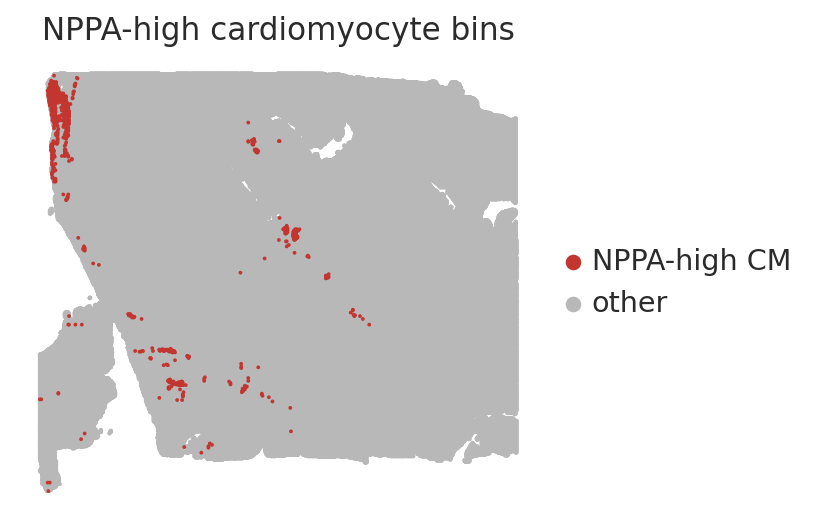

In [29]:
nppa_high, threshold = hhca.tl.gene_high(
    bins, "NPPA", cm_fraction=niche["cm_fraction"], quantile=niche["high_quantile"]
)
n_cardiomyocyte = (bins["frac_CM"] >= niche["cm_fraction"]).sum()
n_nppa_high = nppa_high.sum()
print(f"{n_cardiomyocyte:,} cardiomyocyte bins, {n_nppa_high:,} NPPA-high (at least {threshold:.1f} per 1,000)")

grid = ad.AnnData(obs=bins.copy())
grid.obs["group"] = pd.Categorical(np.where(nppa_high, "NPPA-high CM", "other"))
grid.obsm["spatial"] = bins[["x_um", "y_um"]].to_numpy()
style.set_colors(grid, "group", style.NPPA_HIGH)
nppa_high_on_top = np.argsort(nppa_high)
sq.pl.spatial_scatter(
    grid[nppa_high_on_top],
    color="group",
    shape=None,
    size=2,
    figsize=(5, 5),
    title="NPPA-high cardiomyocyte bins",
)

`hhca.tl.compare_high_low` compares the *NPPA*-high bins with the other cardiomyocyte bins of the section on each
metric, with a one-sided Mann–Whitney U test.

In [30]:
comparison = hhca.tl.compare_high_low(
    bins, "NPPA", niche["metrics"], cm_fraction=niche["cm_fraction"], quantile=niche["high_quantile"]
)
metric_tests = pd.DataFrame(comparison["metrics"]).T
metric_tests[["high_median", "low_median", "high_mean", "low_mean", "alt", "mw_p"]]

,high_median,low_median,high_mean,low_mean,alt,mw_p
nbhd_fibroblast,0.013423,0.00185,0.036097,0.014824,greater,0.0
nbhd_endocardial,0.0,0.0,0.000891,0.000154,greater,0.0
nbhd_vessel,0.009872,0.011429,0.024686,0.023345,greater,0.982348
nbhd_immune,0.0,0.0,0.006112,0.003447,greater,0.0
dist_fibroblast_um,36.055513,63.245553,43.86006,70.231045,less,0.0
dist_endocardial_um,123.693169,819.084855,175.384287,1002.528728,less,0.0
dist_vessel_um,40.0,44.72136,43.847181,49.483238,less,0.0


On this section 990 of the 314,524 cardiomyocyte bins are *NPPA*-high (at least 20 *NPPA* counts per 1,000). They
lie closer than the other cardiomyocyte bins to fibroblast-rich bins (median 36 against 63 µm), to vessel-rich
bins (40 against 45 µm) and to the endocardium (124 against 819 µm).

Does this hold on the other sections? `hhca.tl.niche_tests` runs the comparison for both genes on all 11
sections. Besides the Mann–Whitney test it shuffles the high / low labels among the cardiomyocyte bins 2,000
times, and it adjusts the p values over all tests (Benjamini–Hochberg). The distance to the endocardium is only
meaningful on the three sections that contain the endocardial surface.

In [31]:
endo_sections = cfg["slides"]["endo_sections"]
donor_of_section = {name: {"donor": cfg["sections"][name]["donor"]} for name in all_sections}
pooled_tests = hhca.tl.niche_tests(
    bin_tables,
    niche["genes"],
    niche["metrics"],
    endo_sections,
    labels=donor_of_section,
    cm_fraction=niche["cm_fraction"],
    quantile=niche["high_quantile"],
    n_perm=niche["n_perm"],
    seed=niche["seed"],
    alpha=niche["alpha"],
)
is_nppa = pooled_tests["gene"] == "NPPA"
is_distance = pooled_tests["metric"].str.startswith("dist")
distances = pooled_tests[is_nppa & is_distance & pooled_tests["testable"]]
distance_q = distances.pivot(index="slide", columns="metric", values="mw_q")
distance_q.loc[all_sections].map("{:.1e}".format)

metric,dist_endocardial_um,dist_fibroblast_um,dist_vessel_um
slide,,,
VS_CA_H0054LV_henricke_epi,nan,7.1e-06,1.7e-02
VS_CA_H0054LV_henricke_myo,nan,6.7e-12,1.6e-04
VS_CA_H0054LV_henricke_endo,0.0e+00,2.3e-91,7.2e-08
VS_CA_H0063LV_henricke_epi,nan,4.0e-10,6.9e-12
VS_CA_H0063LV_henricke_myo,nan,1.8e-20,2.0e-15
VS_CA_H0063LV_henricke_endo,6.3e-06,4.2e-28,9.0e-08
VS_BO_HDZ150319_34_myo,nan,2.6e-03,1.3e-04
VS_BO_2024BH-008_myo,nan,8.0e-14,1.3e-09
VS_AH9_LV_FW_epi,nan,4.3e-14,1.5e-08


`hhca.pl.niche_distance` draws the median distances of the two groups per section: to the nearest
fibroblast-rich bin (Fig 3 f), to the nearest vessel-rich bin (Fig 3 g) and to the endocardium (Fig 3 h).

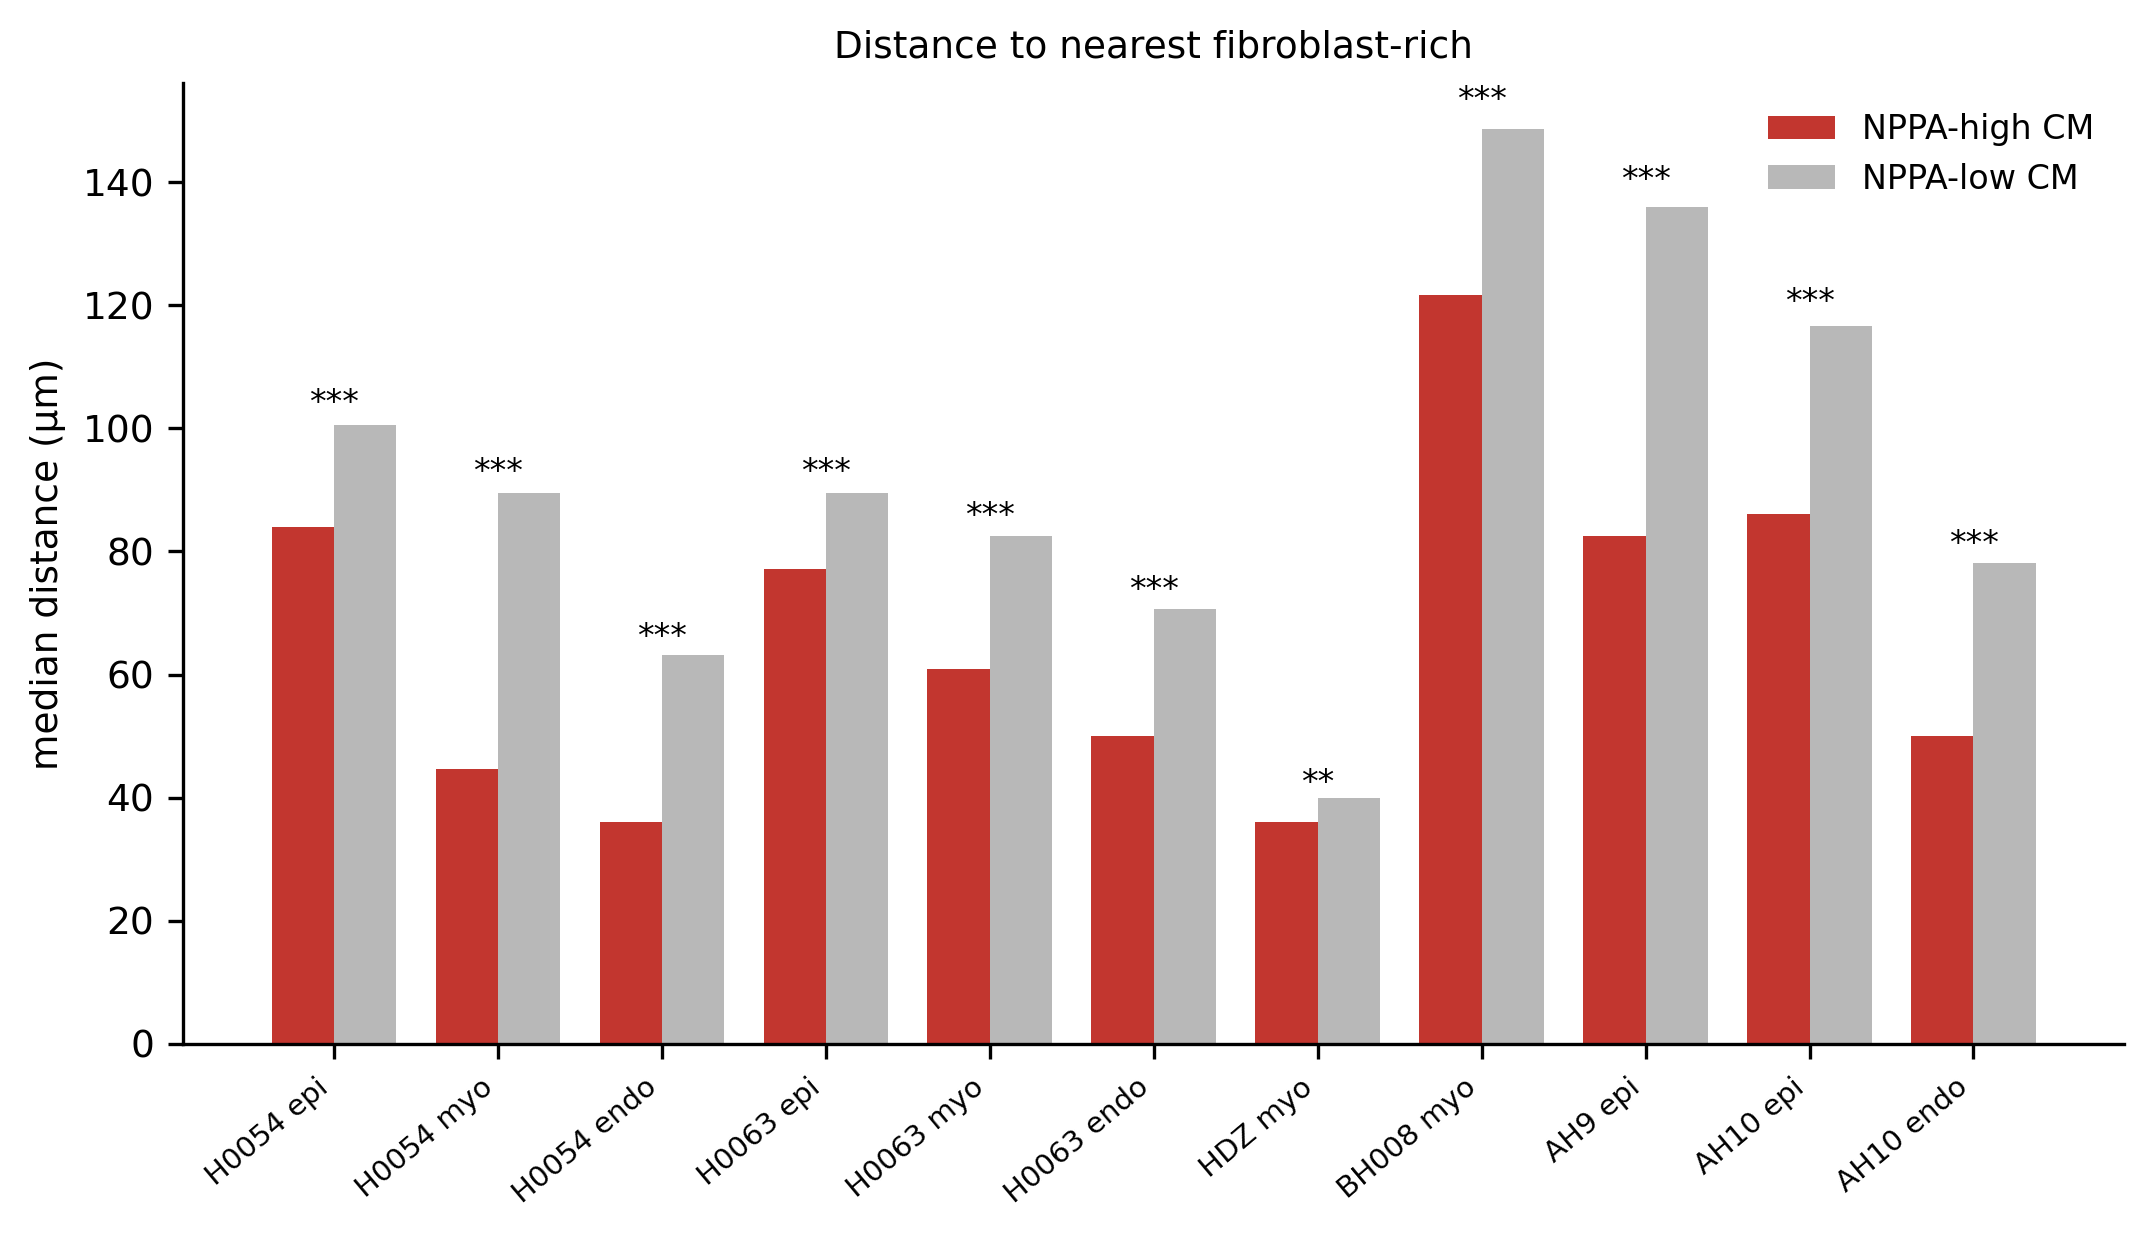

In [32]:
section_labels = {}
for name in all_sections:
    donor, layer = section_table.loc[name, ["donor", "layer"]]
    section_labels[name] = f"{donor} {layer}"
fig = hhca.pl.niche_distance(pooled_tests, "dist_fibroblast_um", section_labels)

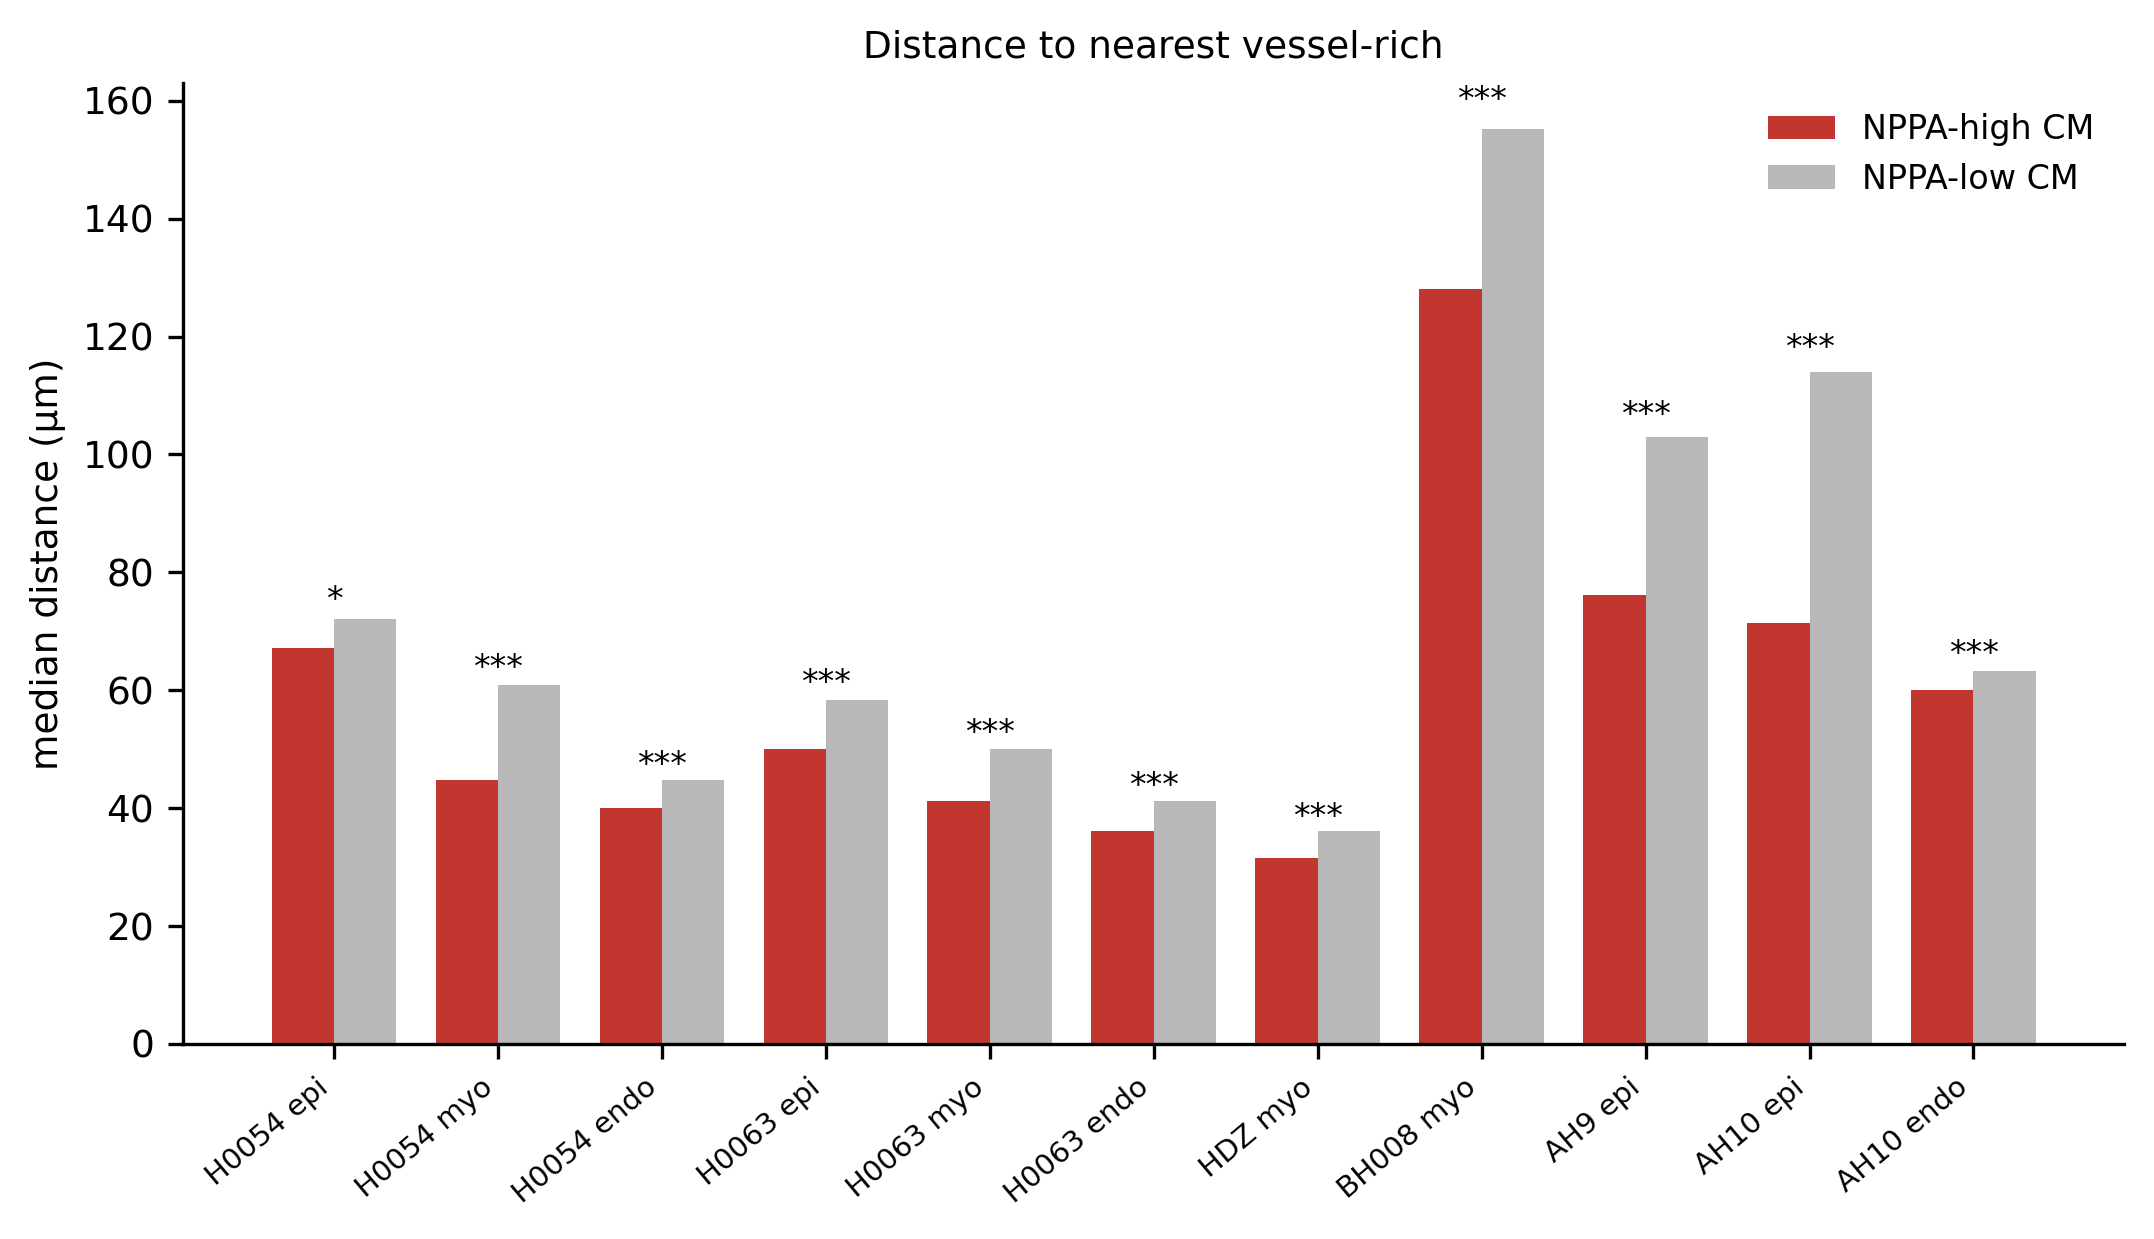

In [33]:
fig = hhca.pl.niche_distance(pooled_tests, "dist_vessel_um", section_labels)

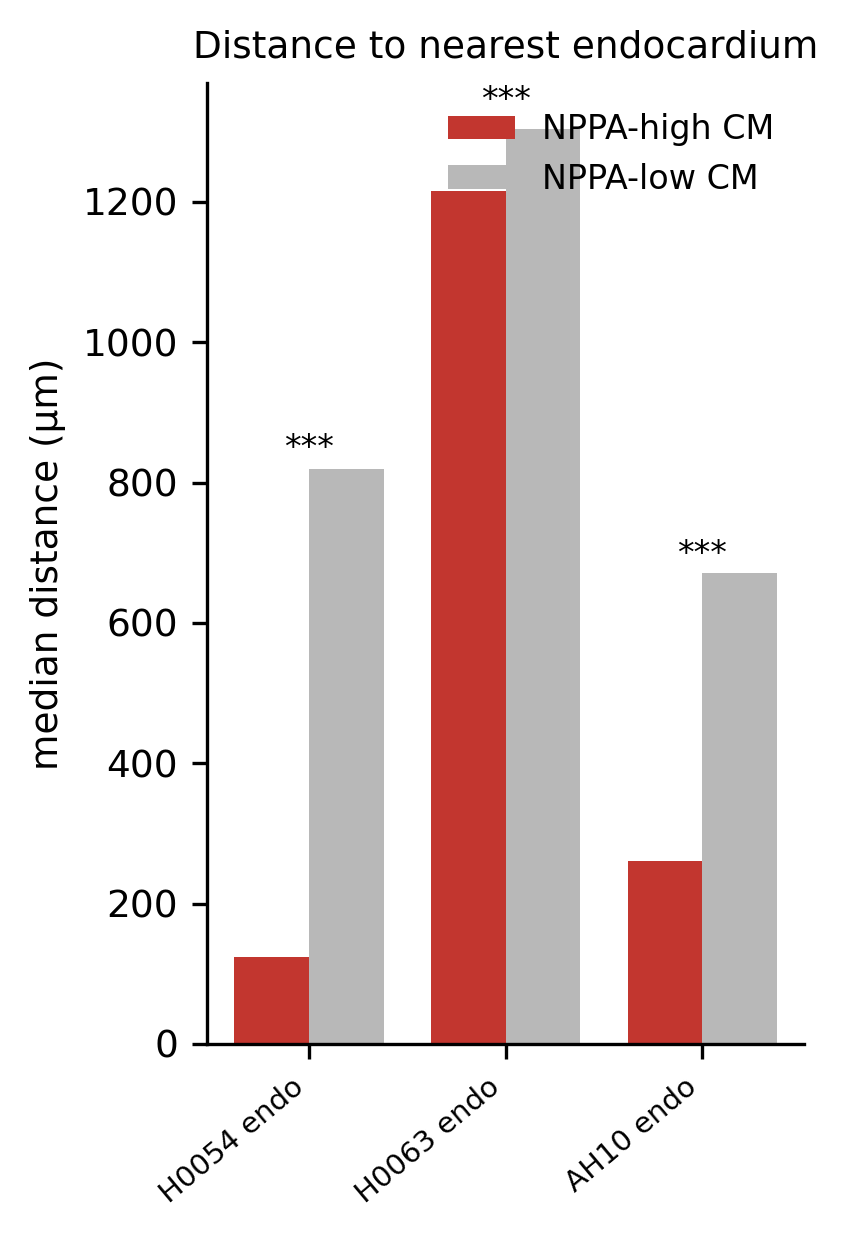

In [34]:
endo_labels = {name: section_labels[name] for name in endo_sections}
fig = hhca.pl.niche_distance(pooled_tests, "dist_endocardial_um", endo_labels)

`hhca.tl.niche_consistency` counts the sections on which the difference is significant in the expected direction.

In [35]:
nppa_consistency = {
    "fibroblast-rich": hhca.tl.niche_consistency(pooled_tests, "dist_fibroblast_um", all_sections)["NPPA"],
    "vessel-rich": hhca.tl.niche_consistency(pooled_tests, "dist_vessel_um", all_sections)["NPPA"],
    "endocardium": hhca.tl.niche_consistency(pooled_tests, "dist_endocardial_um", endo_sections)["NPPA"],
}
consistency_table = pd.DataFrame(nppa_consistency).T
consistency_table[["n_slides", "n_sig", "med_log2"]].round(2)

,n_slides,n_sig,med_log2
fibroblast-rich,11.0,11.0,-0.37
vessel-rich,11.0,11.0,-0.21
endocardium,3.0,3.0,-0.98


*NPPA*-high cardiomyocyte bins are closer to fibroblast-rich bins and to vessel-rich bins on all 11 sections, and
closer to the endocardium on all 3 endocardial sections (adjusted q < 0.05).

## Genes that change across the wall

The stress score was a set of genes chosen beforehand. Which genes change most consistently from epicardium to
endocardium if we let the data choose? For this we need a coordinate across the wall for every cardiomyocyte bin.

`hhca.tl.celltype_bins` loads the ventricular-cardiomyocyte bins of a section with all genes, log-normalised.

In [36]:
transmural = cfg["transmural"]
cm_section = hhca.tl.celltype_bins(adata, ventricular)
cm_section

AnnData object with n_obs × n_vars = 6621934 × 18085
    obs: 'x_um', 'y_um'
    var: 'n_bins'
    obsm: 'spatial'

A section does not come with a label for its epicardial and endocardial side. `hhca.tl.transmural_coordinate`
finds the direction from a marker score (endocardial markers *NPPA*, *NPPB*, *POSTN* minus five epicardial
markers), takes the tissue boundary at the two ends of this direction as the two faces and solves the Laplace
equation in between. The result, `cm_section.obs["phi"]`, runs from 0 at the epicardial face to 1 at the
endocardial face.

96.5% of the bins have a coordinate


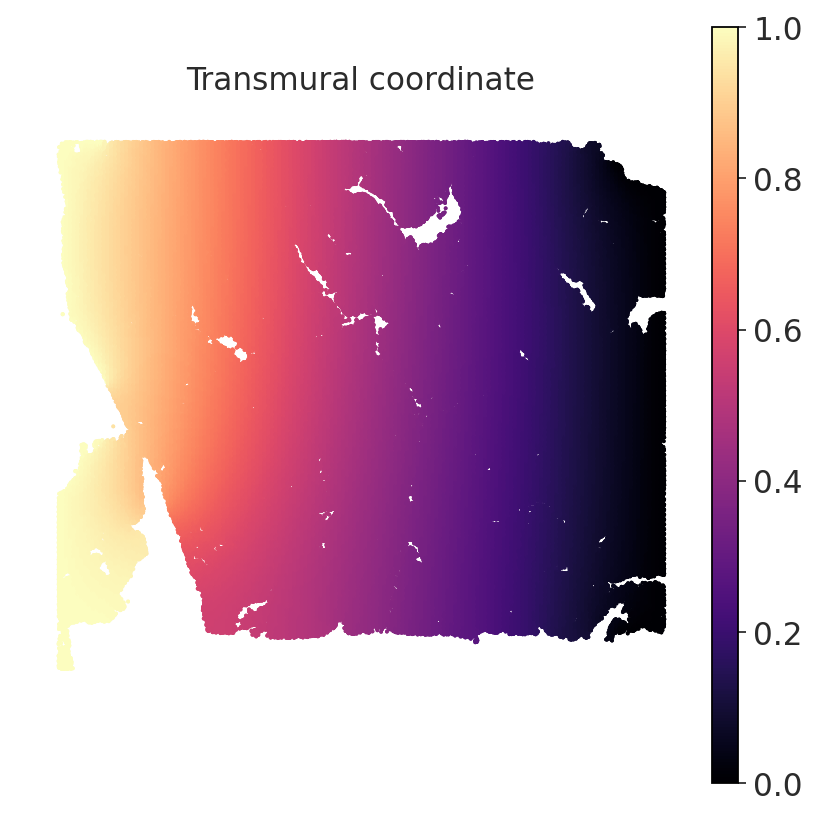

In [37]:
hhca.tl.transmural_coordinate(
    cm_section,
    transmural["endo_markers"],
    transmural["epi_markers"],
    grid_um=transmural["grid_um"],
    face_fraction=transmural["face_fraction"],
)
share_with_coordinate = np.isfinite(cm_section.obs["phi"]).mean()
print(f"{share_with_coordinate:.1%} of the bins have a coordinate")
display_step = 25  # draw every 25th bin
sq.pl.spatial_scatter(
    cm_section[::display_step],
    color="phi",
    shape=None,
    size=2,
    cmap=style.SEQUENTIAL,
    figsize=(5, 5),
    title="Transmural coordinate",
)

The three sections of a donor follow each other across the wall, so the epicardial section covers positions 0–1,
the mid-myocardial section 1–2 and the endocardial section 2–3. `hhca.tl.wall_bins` cuts this range into 45 bins,
15 per section.

In [38]:
wall_bin = hhca.tl.wall_bins(
    cm_section, "endo", layers=transmural["layers"], bins_per_section=transmural["bins_per_section"]
)
in_wall = wall_bin[wall_bin >= 0]
bins_per_wall_bin = pd.Series(in_wall).value_counts().sort_index()
bins_per_wall_bin.to_frame("cardiomyocyte bins").T

,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44
cardiomyocyte bins,510649,483340,494691,519198,489040,440485,478096,494327,478201,379448,327994,278070,271825,288907,454437


`hhca.tl.transmural_profiles` runs these three steps on every section of a donor and sums the expression of all
genes per wall bin. We call it once per donor; donor AH10 has no mid-myocardial section, so the middle third of
its wall is not sampled.

In [39]:
section_of = {}
for name in all_sections:
    donor, layer = section_table.loc[name, ["donor", "layer"]]
    section_of[donor, layer] = name

donor_sections = {}
for donor in transmural["donors"]:
    donor_sections[donor] = {}
    for layer in transmural["layers"]:
        if (donor, layer) in section_of:
            donor_sections[donor][layer] = sections[section_of[donor, layer]]

wall_profiles = {}
diagnostics = {}
for donor in transmural["donors"]:
    wall_profiles[donor] = hhca.tl.transmural_profiles(
        donor_sections[donor],
        transmural["endo_markers"],
        transmural["epi_markers"],
        layers=transmural["layers"],
        bins_per_section=transmural["bins_per_section"],
        cell_type=ventricular,
        grid_um=transmural["grid_um"],
        face_fraction=transmural["face_fraction"],
    )
    diagnostics[donor] = pd.DataFrame(wall_profiles[donor]["diagnostics"])
pd.concat(diagnostics, names=["donor"]).droplevel(1)

,layer,n_cm,marker_axis_R2,phi_ok
donor,,,,
H0054,epi,7405224,0.000013,7213243
H0054,myo,7475856,0.000007,7292045
H0054,endo,6621934,0.000134,6388708
H0063,epi,7246811,0.000032,6997854
H0063,myo,6583623,0.000013,6345617
H0063,endo,5475494,0.000067,5323300
AH10,epi,4471010,0.000467,4134851
AH10,endo,6155020,0.002165,5855710


For every gene and donor, `hhca.tl.transmural_rho` correlates the smoothed, z-scored profile with the position in
the wall (Spearman ρ). The consensus is the mean ρ over the donors, and a gene is sign-consistent when ρ has the
same sign in all of them. Genes detected in fewer than 0.2% of the cardiomyocyte bins are not considered.

In [40]:
ranking = hhca.tl.transmural_rho(wall_profiles, min_detection=transmural["min_detection"], sigma=transmural["sigma"])
ranking = ranking.sort_values("consensus_rho_3donor", ascending=False).reset_index(drop=True)
eligible = ranking["in_universe"] & ranking["sign_consistent_3donor"]
n_in_universe = ranking["in_universe"].sum()
n_eligible = eligible.sum()
print(f"{len(ranking):,} genes, {n_in_universe:,} in the universe, {n_eligible:,} sign-consistent")
rho_columns = ["gene", "rho_H0054", "rho_H0063", "rho_AH10", "consensus_rho_3donor"]
ranking.loc[eligible, rho_columns].head(8).round(3)

16,859 genes, 1,004 in the universe, 277 sign-consistent


,gene,rho_H0054,rho_H0063,rho_AH10,consensus_rho_3donor
104,MMP2,0.702,0.411,0.764,0.626
131,ATP1A2,0.742,0.434,0.659,0.612
183,SPARC,0.803,0.455,0.514,0.591
194,COL1A2,0.682,0.669,0.413,0.588
202,TNXB,0.515,0.470,0.764,0.583
225,NCAM1,0.766,0.212,0.738,0.572
235,EHBP1L1,0.729,0.311,0.672,0.571
238,RAB13,0.706,0.485,0.517,0.570


The top of this list contains genes such as *MMP2* and *SPARC* that are made by stromal cells: a cardiomyocyte
bin of 2 µm still catches some transcripts of its neighbours, and stromal cells are more frequent near the
endocardium. We therefore restrict the search to genes that are cardiomyocyte-specific in the atlas.
`hhca.tl.cardiomyocyte_specificity` calls a gene `cm_safe` when ventricular cardiomyocytes express it (mean of at
least 0.05) and a cardiomyocyte type is its top expresser.

In [41]:
specificity_cfg = cfg["specificity"]
specificity = hhca.tl.cardiomyocyte_specificity(
    atlas["mean"],
    min_ventricular_mean=specificity_cfg["min_ventricular_mean"],
    min_ratio=specificity_cfg["min_ratio"],
)
gene_specificity = specificity.drop_duplicates("gene").set_index("gene")
specificity_columns = ["VentCM", "top_nonCM", "CM_over_topNonCM", "cm_safe", "cm_call"]
ranking = ranking.merge(gene_specificity[specificity_columns], left_on="gene", right_index=True, how="left")
ranking["cm_safe"] = ranking["cm_safe"].fillna(False).astype(bool)
ranking.loc[eligible, "cm_call"].value_counts().to_frame("sign-consistent genes")

,sign-consistent genes
cm_call,
CM-expressed but broad (not specific),104
CM-specific,92
non-CM (likely contamination),72
CM-highest but low-expressed,9


`hhca.tl.select_modules` takes the six `cm_safe` genes with the highest consensus ρ (rising towards the
endocardium) and the four with the lowest (rising towards the epicardium).

In [42]:
modules = hhca.tl.select_modules(ranking, n_endo=transmural["n_endo"], n_epi=transmural["n_epi"], only="cm_safe")
module_genes = modules["endo"] + modules["epi"]
shown_columns = ["rho_H0054", "rho_H0063", "rho_AH10", "consensus_rho_3donor", "VentCM", "top_nonCM"]
ranking.set_index("gene").loc[module_genes, shown_columns].round(3)

,rho_H0054,rho_H0063,rho_AH10,consensus_rho_3donor,VentCM,top_nonCM
gene,,,,,,
C15orf41,0.736,0.148,0.663,0.515,1.290,Lymphoid Cells (Proliferating)
MYH14,0.465,0.640,0.340,0.482,0.180,Adipocytes
MYH7,0.762,0.209,0.436,0.469,1.344,Mast cells
OBSL1,0.533,0.599,0.252,0.462,0.117,Unassigned
TNNT1,0.736,0.480,0.164,0.460,0.181,Unassigned
MYOM3,0.632,0.296,0.444,0.457,0.611,Unassigned
RABGAP1L,-0.927,-0.852,-0.616,-0.798,1.267,NK cells
NMRK2,-0.940,-0.643,-0.568,-0.717,0.278,Unassigned
MYL7,-0.888,-0.531,-0.616,-0.678,0.240,Unassigned


`hhca.tl.module_profiles` returns the wall profile of these genes per donor, and `hhca.pl.transmural_modules`
draws Fig 3 i: the mean of the z-scored profiles over the donors, with their spread as a band.

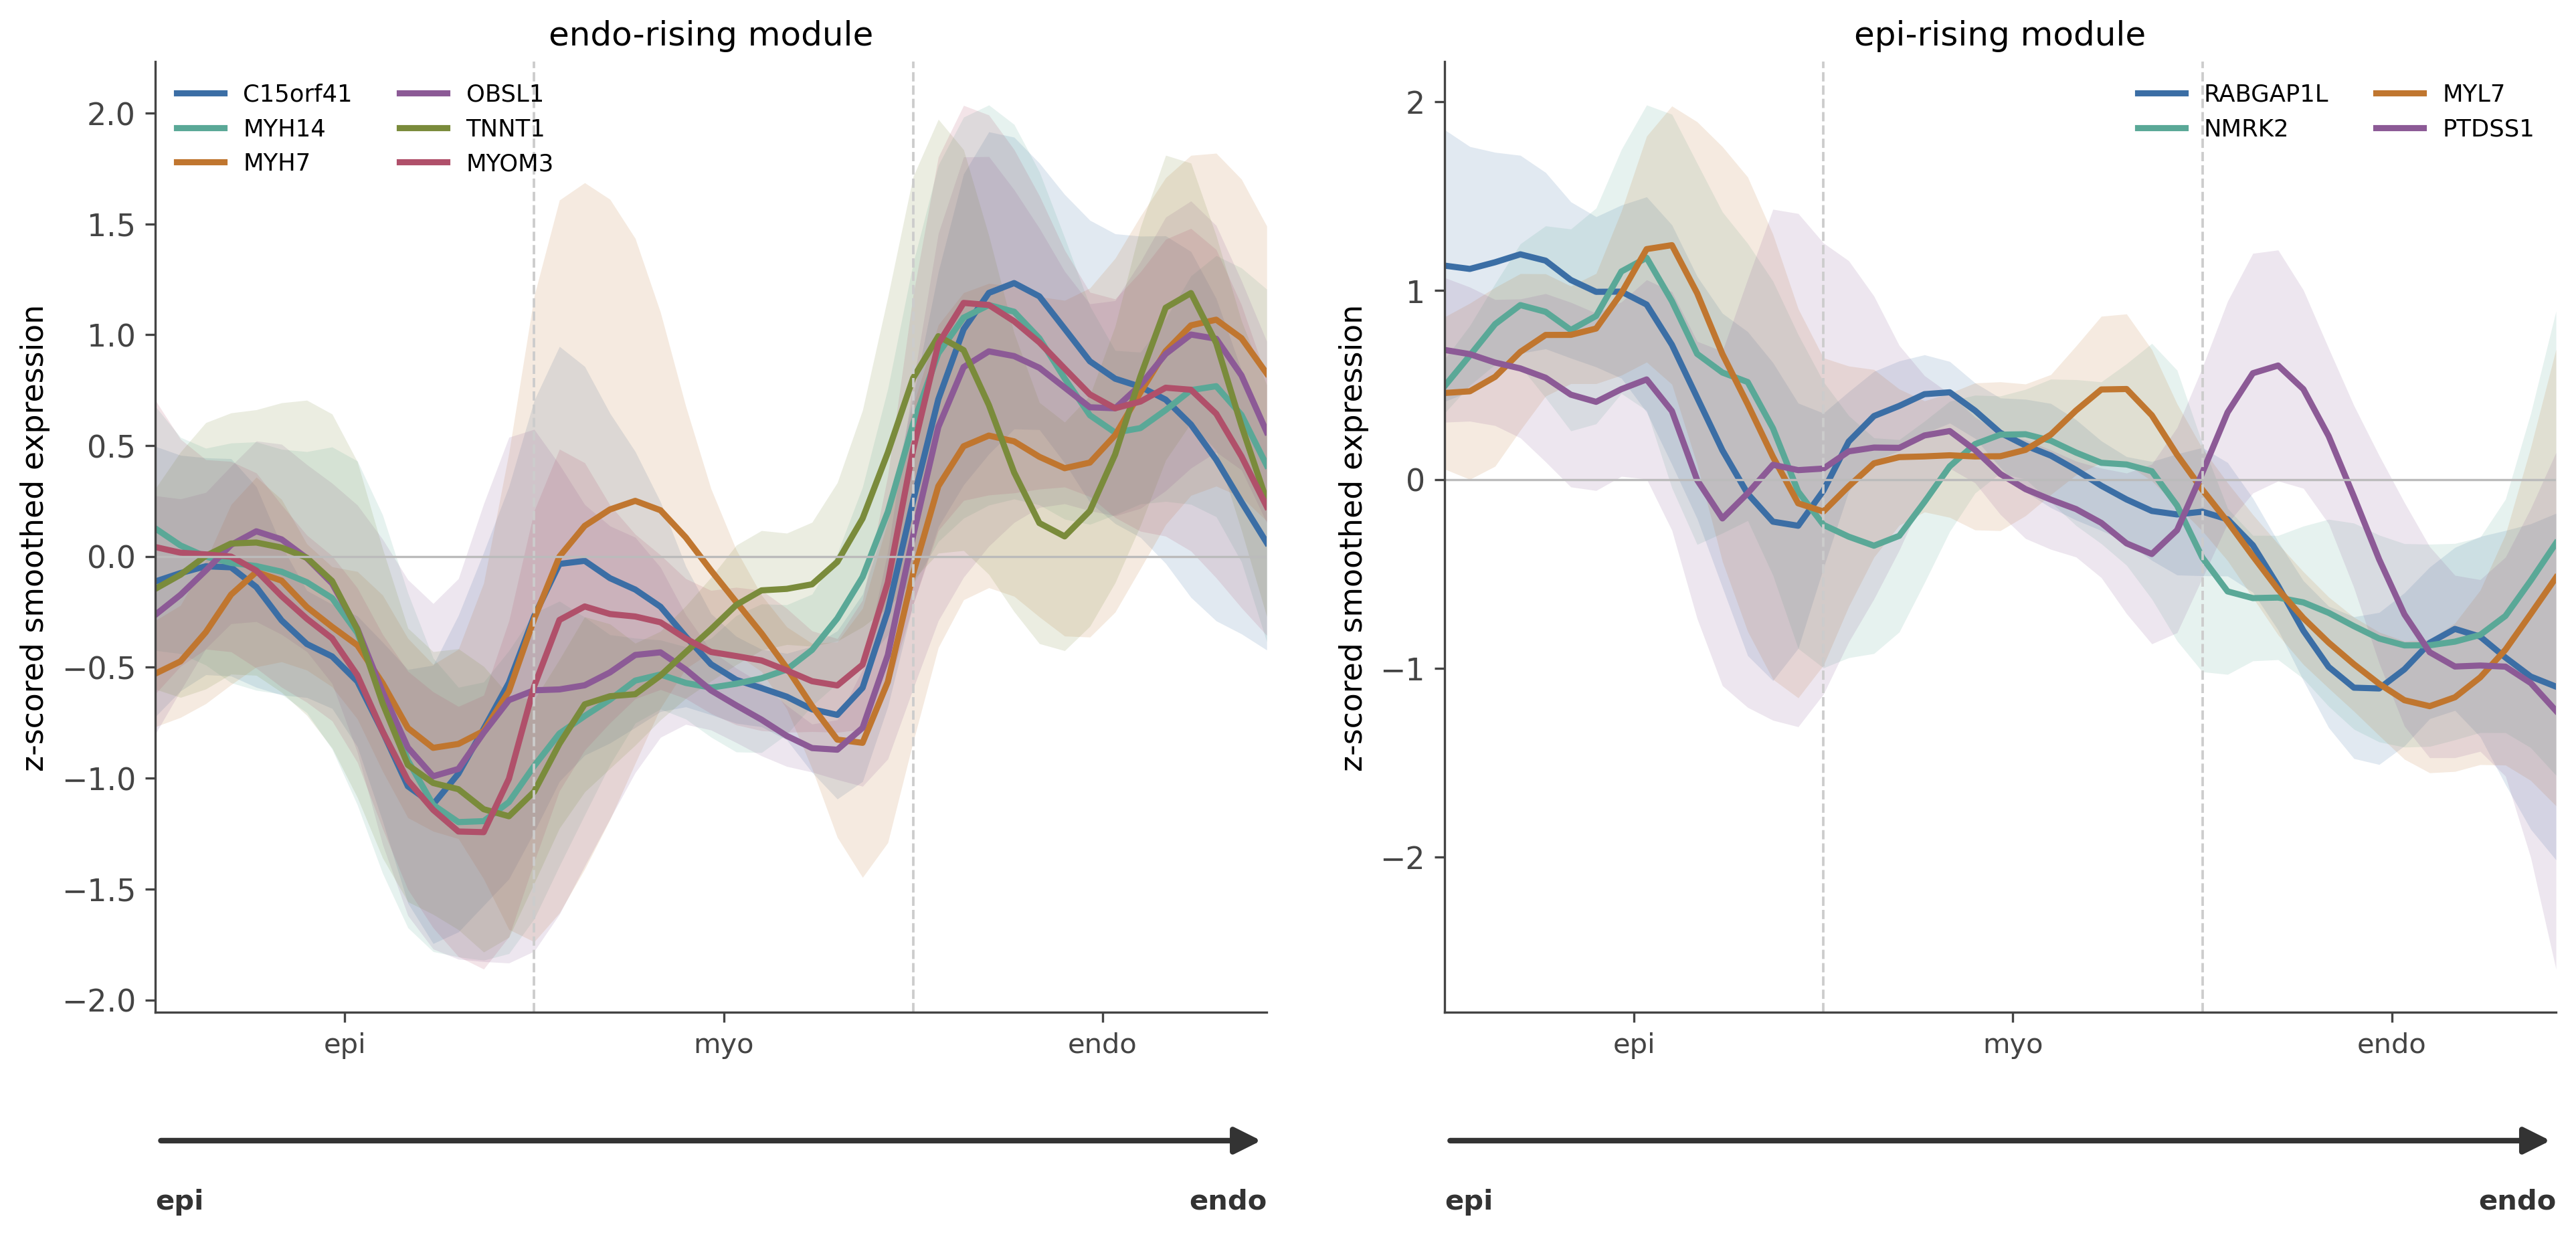

In [43]:
module_tables = hhca.tl.module_profiles(wall_profiles, module_genes)
fig = hhca.pl.transmural_modules(module_tables, modules, transmural["sigma"])

Of the 16,859 detected genes, 1,004 pass the detection threshold and 277 of these change in the same direction in
all three donors; 92 of the 277 are cardiomyocyte-specific. Six genes rise towards the endocardium (*C15orf41*,
*MYH14*, *MYH7*, *OBSL1*, *TNNT1*, *MYOM3*; consensus ρ 0.46 to 0.52) and four towards the epicardium (*RABGAP1L*,
*NMRK2*, *MYL7*, *PTDSS1*; ρ −0.60 to −0.80).

## Transcript and protein gradients

Deep visual proteomics (DVP) measured cardiomyocyte proteins at the same three positions of the wall in two
cohorts. Do the proteins change in the same direction as the transcripts?

On the transcript side we use a simpler read-out than the wall profile: one pseudobulk per section.
`hhca.tl.section_pseudobulk` sums the raw counts of the ventricular-cardiomyocyte bins of the eight transmural
sections.

In [44]:
fig3l = cfg["fig3l"]
samples = {}
for donor, by_layer in donor_sections.items():
    for layer, section_bins in by_layer.items():
        samples[f"{donor}_{layer}"] = section_bins
pseudobulk = hhca.tl.section_pseudobulk(samples, cell_type=ventricular, chunk=fig3l["chunk"])
pseudobulk["meta"]

,sample,n_bins,n_cell_type,cell_type_counts,all_counts
0,H0054_epi,7633492,7405224,115957007.0,119005160.0
1,H0054_myo,7701469,7475856,107263205.0,110702957.0
2,H0054_endo,7015351,6621934,120834694.0,128211946.0
3,H0063_epi,7442651,7246811,139177958.0,142696088.0
4,H0063_myo,6798677,6583623,123455100.0,127145412.0
5,H0063_endo,5739584,5475494,94541960.0,98748153.0
6,AH10_epi,5066167,4471010,26486466.0,28257737.0
7,AH10_endo,6691420,6155020,31363629.0,34322630.0


`hhca.tl.transmural_slopes` fits, for every gene, a line through log1p CP10k of the eight pseudobulks against the
position of the section (0, 1, 2), and one line per donor.

In [45]:
expression = hhca.tl.log_cp10k_pseudobulk(pseudobulk["cell_type"], transmural["donors"], transmural["layers"])
slopes = hhca.tl.transmural_slopes(expression, transmural["donors"], transmural["layers"])
shown_genes = ["NPPA", "NPPB", "MYH7", "MYL7"]
shown_columns = ["slope", "slope_H0054", "slope_H0063", "slope_AH10", "sign_consistent"]
slopes.loc[shown_genes, shown_columns].round(3)

,slope,slope_H0054,slope_H0063,slope_AH10,sign_consistent
gene,,,,,
NPPA,0.343,0.314,-0.043,0.759,False
NPPB,0.126,0.032,0.007,0.340,True
MYH7,0.084,0.129,0.069,0.054,True
MYL7,-0.306,-0.464,-0.083,-0.371,True


The DVP table holds, per protein and cohort, the slope across the wall with its p value. `hhca.tl.protein_slopes`
averages the two cohorts; we join the transcript slopes by gene name.

In [46]:
dvp_table = fill(cfg["dvp"]["all"], resolve_roots(cfg))
proteins = pd.read_excel(dvp_table)
protein_slopes = hhca.tl.protein_slopes(proteins)
joined = slopes.join(protein_slopes[["protein_CM_consensus"]], how="inner")
joined.index = joined.index.str.upper()
joined = joined[~joined.index.duplicated()]
print(f"{len(proteins):,} proteins, {len(joined):,} genes with a transcript and a protein slope")
all_genes = hhca.tl.slope_concordance(joined["slope"], joined["protein_CM_consensus"])
pd.Series(all_genes).to_frame("all genes").T

6,521 proteins, 3,858 genes with a transcript and a protein slope


,n,rho,p,sign_agree
all genes,3851.0,0.249926,6.332057e-56,0.578291


Most proteins do not change across the wall, so a comparison over all genes is dominated by noise. Following the
DVP analysis, we keep the proteins with p < 0.05 and the same slope sign in both cohorts, and of these the genes
that are cardiomyocyte-specific in the atlas (`hhca.tl.dvp_gene_sets`).

In [47]:
gene_sets = hhca.tl.dvp_gene_sets(proteins, gene_specificity, fig3l["structural_axis"], p_max=fig3l["p_max"])
concordance_rows = {}
for name, genes in gene_sets.items():
    transcript_slope = joined["slope"].reindex(genes)
    protein_slope = joined["protein_CM_consensus"].reindex(genes)
    row = {"genes": len(genes)}
    row.update(hhca.tl.slope_concordance(transcript_slope, protein_slope))
    concordance_rows[name] = row
concordance = pd.DataFrame(concordance_rows).T
concordance

,genes,n,rho,p,sign_agree
curated17,17.0,17.0,0.546569,2.319384e-02,0.823529
dvp_rule,225.0,211.0,0.714454,2.949011e-34,0.815166
dvp_rule_cmexpr,131.0,126.0,0.730370,2.884806e-22,0.825397
dvp_rule_cmratio,56.0,55.0,0.814214,4.047622e-14,0.872727
dvp_rule_cmsafe,44.0,43.0,0.829055,6.592547e-12,0.883721


`hhca.pl.slope_concordance` draws Fig 3 l for the set `dvp_rule_cmsafe`.

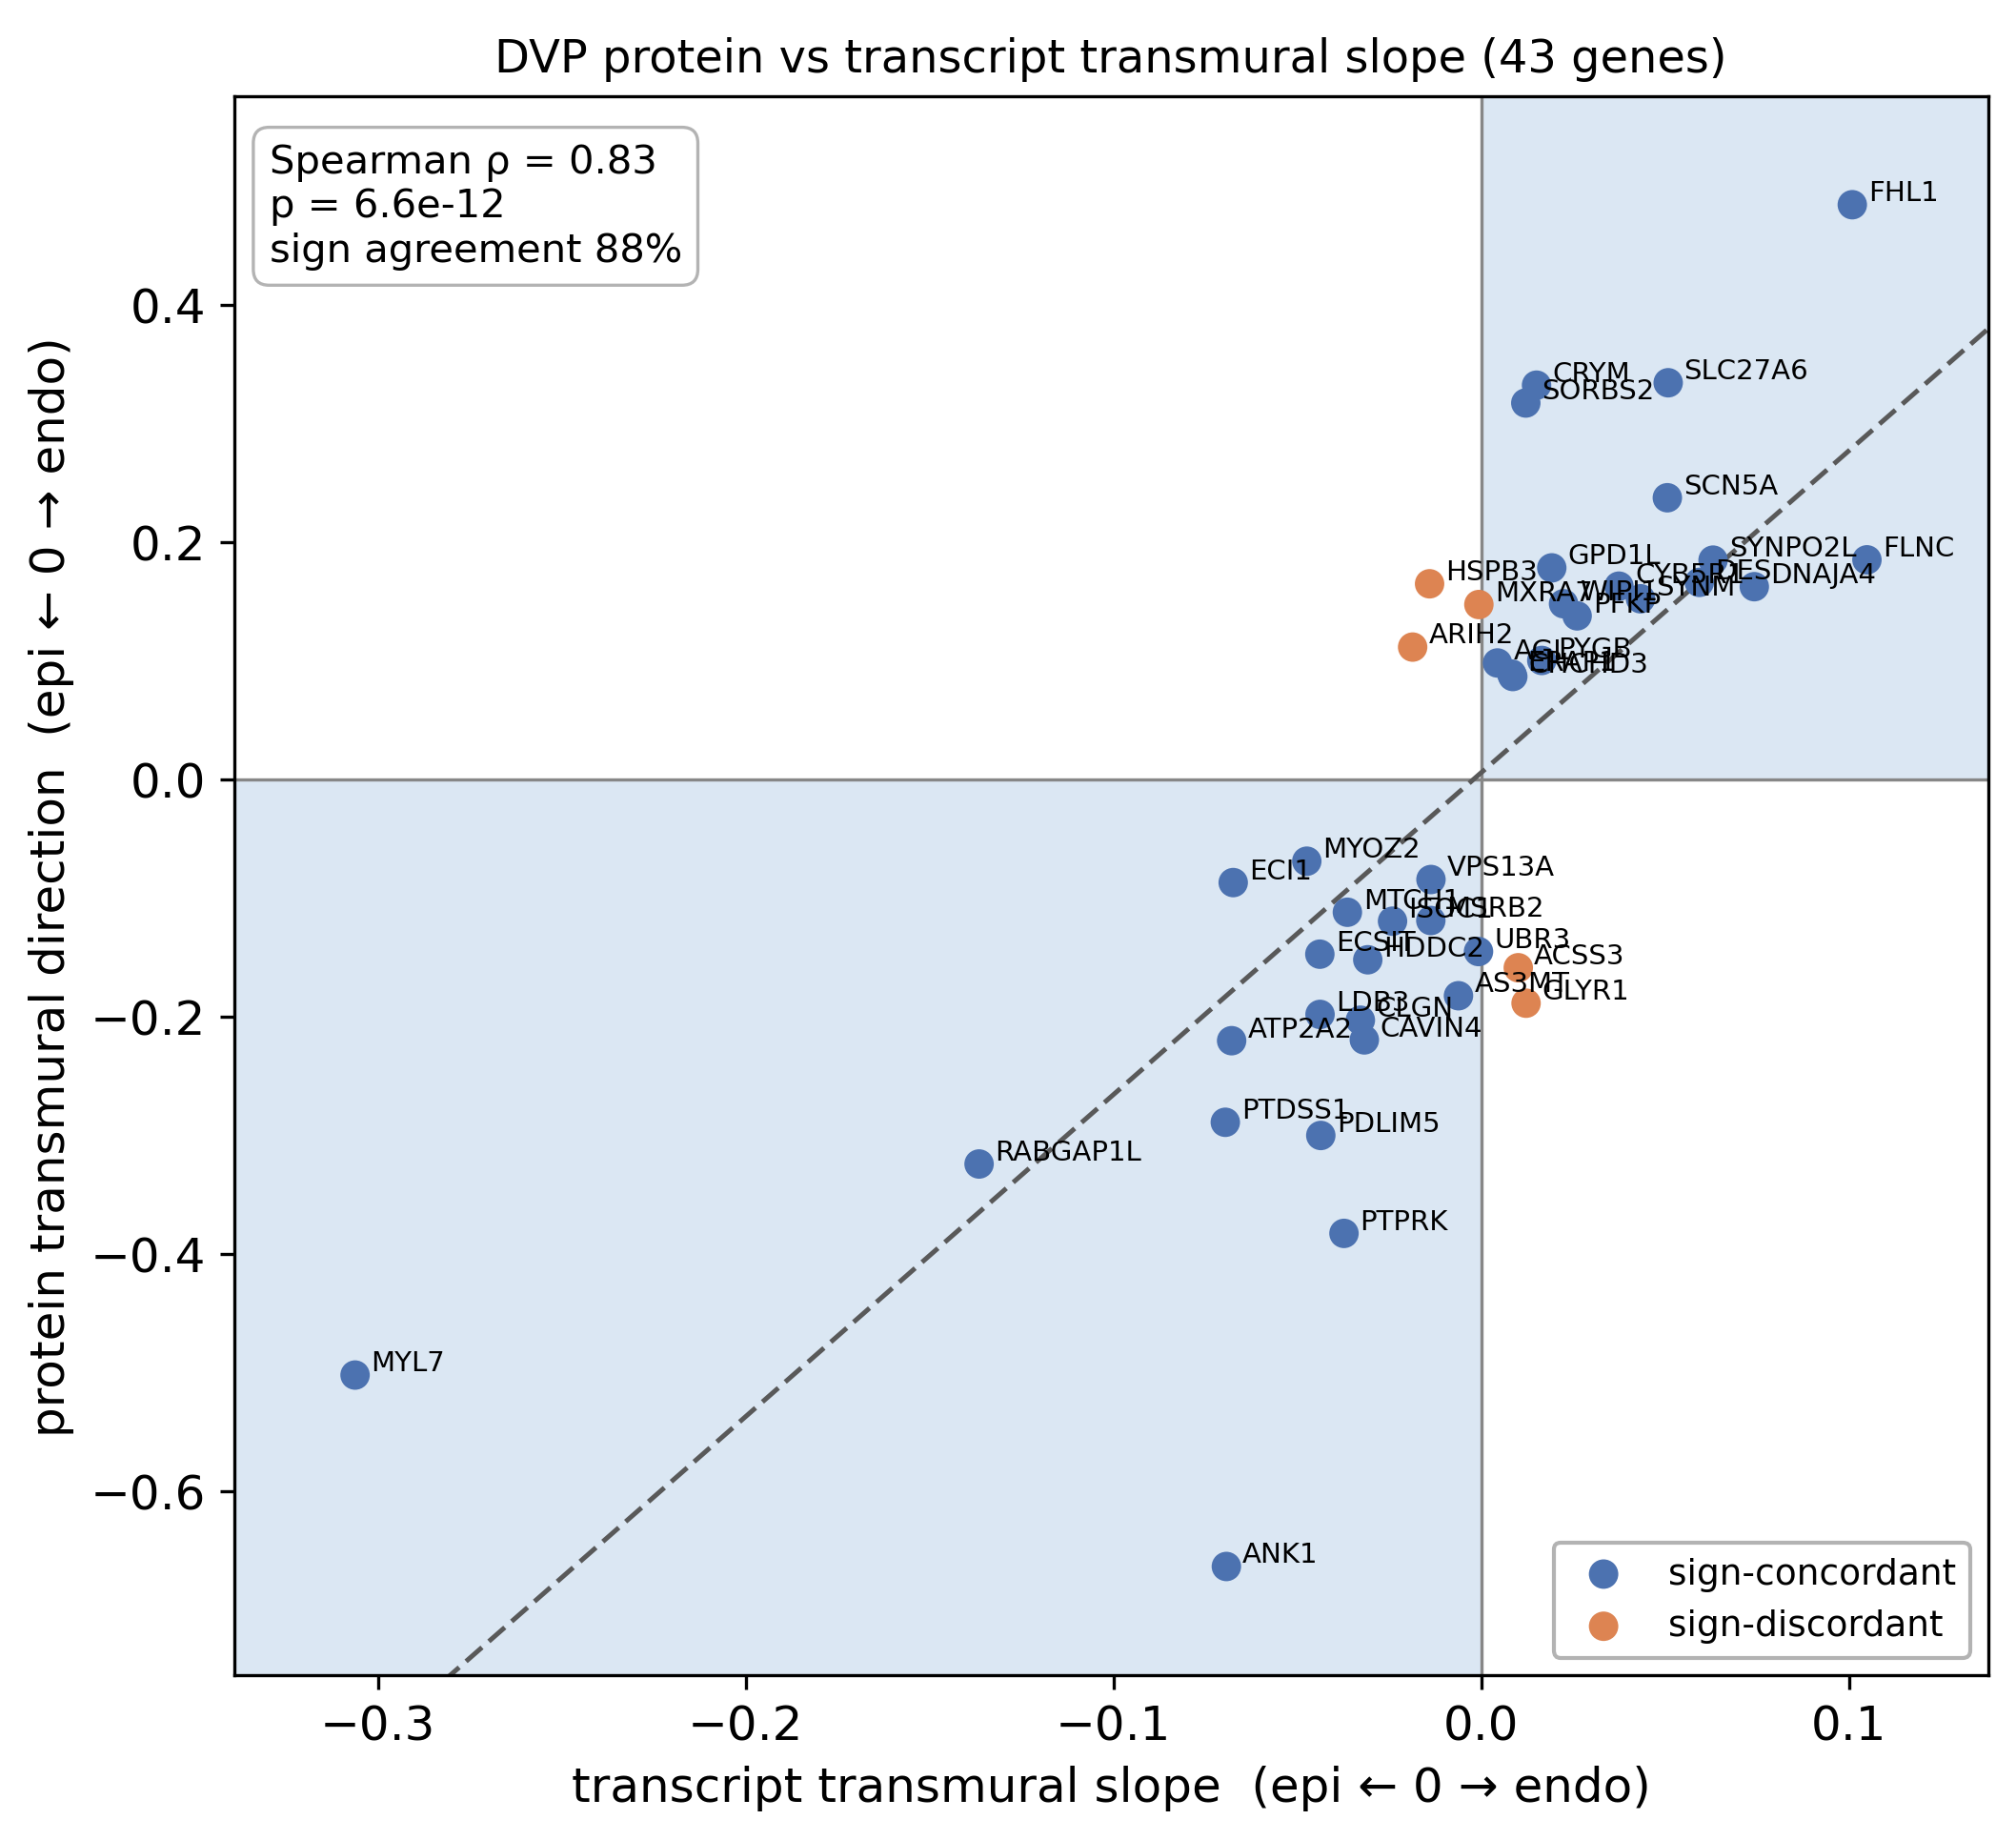

In [48]:
chosen = joined.reindex(gene_sets[cfg["panels"]["fig3l_gene_set"]])
slope_pairs = pd.DataFrame(
    {
        "gene": chosen.index,
        "transcript_slope": chosen["slope"].to_numpy(),
        "protein_slope": chosen["protein_CM_consensus"].to_numpy(),
    }
)
fig = hhca.pl.slope_concordance(slope_pairs)

Over all 3,851 genes with a transcript and a protein slope, the two agree only weakly (ρ = 0.25, 58% with the same
sign). For the 43 cardiomyocyte-specific genes whose protein changes in both cohorts they agree well: ρ = 0.83
(p = 6.6e-12), and 88% of the genes have the same sign.

Fig 3 k, the volcano plots of the DVP proteome, is drawn from the protein-group matrices of the proteomics
experiment (`scripts/cardiomyocyte/dvp_trend.py`), which are not among the inputs of this repository, so it is
not shown here.

## Key takeaways

- The Level-3 labels carry the expected genes: 41 of 45 hand-picked markers are highest in their own label, and all
  23 FICTURE factors match their own atlas type best (mean r = 0.83).
- The stress score of ventricular cardiomyocytes is higher on the endocardial side of the wall of donor H0054 (section
  mean 0.027, against −0.013 and −0.011).
- *NPPA*-high cardiomyocytes sit closer to fibroblast-rich and vessel-rich tissue on all 11 sections, and closer to
  the endocardium on all 3 endocardial sections.
- Ten cardiomyocyte-specific genes follow the wall in three donors: six rise towards the endocardium and four
  towards the epicardium.
- Transcript slopes across the wall agree with DVP protein slopes for cardiomyocyte-specific genes (ρ = 0.83, 88%
  same sign, 43 genes).
- Every step is one function of `hhca.tl` and every panel one function of `hhca.pl`, so the same code runs here
  and in the pipeline scripts.